In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = '7' #0,

import geopandas as gpd
import numpy as np
import os
#os.environ["CUDA_VISIBLE_DEVICES"] = "1,7"

import torch
torch.cuda.device_count()

# geo2llm_demo.py
import math
import random
from typing import List, Dict
from tqdm import tqdm

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForCausalLM
# from transformers import AdamW
from torch.optim import AdamW

import re
import matplotlib.pyplot as plt
from accelerate import Accelerator


/home/chenchu/.conda/envs/next/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed(42)

In [3]:
class Geo2VecEncoder(nn.Module):
    """
    Example encoder: MLP -> reshape to (L_geo, dim)
    """
    def __init__(self, input_dim: int, hidden=256,  out_dim=256):
        super().__init__()
        self.out_dim = out_dim
        #self.cnn = LengthPredictorCNN(embedding_dim=input_dim)
        self.cnn = LengthPredictorRegion(embedding_dim=input_dim)
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, out_dim)
        )

    def forward(self, x: torch.Tensor):
        # x: (B,group_size, H, W) 
        x = self.cnn(x)  # (B,group_size, 1,(H, W)) -> (B, input_dim)
        out = self.mlp(x)  # (B,out_dim)
        return out
    
    @property
    def device(self):
        return next(self.parameters()).device

# class LengthPredictorCNN(nn.Module):
#     def __init__(self, embedding_dim=128):
#         super(LengthPredictorCNN, self).__init__()
#         self.features = nn.Sequential(
#             nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
#             nn.ReLU(),
#             nn.MaxPool2d(2, 2), 

#             nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
#             nn.ReLU(),
#             nn.MaxPool2d(2, 2), 

#             nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
#             nn.ReLU(),
#             nn.MaxPool2d(2, 2)
#         )
        
#         self.encoder = nn.Sequential(
#             nn.Flatten(),
#             nn.Linear(64 * 4 * 4, embedding_dim),
#             nn.ReLU()
#         )

#     def forward(self, x):
#         if len(x.shape) == 5:
#             B, group_size, _, H, W = x.shape
#             x = x.view(B * group_size, 1, H, W)  # (B*group_size, 1, H, W)
#         x = self.features(x)
#         embedding = self.encoder(x)

#         embedding = embedding.view(B, group_size, -1)  # (B, group_size, embedding_dim)
#         return embedding


import torch
import torch.nn as nn

class MaskPooling(nn.Module):
    def __init__(self, mask_threshold=0.5):
        super().__init__()
        self.mask_threshold = mask_threshold

    def forward(self, x, mask_list, return_list=False, return_mask=False):
        """
        Args:
            x: [B, (HW), C]
            mask_list: List( tensor[M, IH, IW] )
        """
        batch_size = x.size(0)
        if mask_list is None:
            mask_list = [None for i in range(batch_size)]

        output = []
        attn_mask_list = []
        for i in range(batch_size):
            x_len = x.size(1)
            mask = mask_list[i]
            if mask is None:
                output.append(None)
                attn_mask_list.append(None)
            else:
                mask_hw = mask.size(-1) * mask.size(-2)
                scale_factor = (x_len / mask_hw) ** 0.5

                # CRITICAL FIX: Removed mask.detach() to allow backpropagation 
                # through the internal mask generation layer.
                mask = mask.float()[None, ...]
                mask = nn.functional.interpolate(mask, scale_factor=scale_factor, mode="bilinear")
                mask = mask.to(x.dtype)
                mask = mask[0]
                feature = x[i]

                denorm = mask.sum(dim=(-1, -2)) + 1e-8  # M
                denorm = denorm.unsqueeze(-1)  # M, 1

                mask = mask.flatten(start_dim=1)  # M, H, W -> M, HW

                attn_mask_list.append((mask > self.mask_threshold).to(mask.dtype))  # M, HW

                mask_pooled_x = torch.einsum(
                    "lc,ml->mc",
                    feature,
                    mask / denorm,
                )
                output.append(mask_pooled_x)

        if return_list:
            if return_mask:
                return output, attn_mask_list
            return output
        else:
            output = torch.cat(output)
            return output

class LengthPredictorCNN(nn.Module):
    def __init__(self, embedding_dim=128):
        super(LengthPredictorCNN, self).__init__()
        
        # Keep your original feature extractor structure
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), 

            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), 

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        
        # INTERNAL MASK GENERATOR: Uses spatial features to learn a 
        # localized region mask [B, 1, H_f, W_f] for MaskPooling.
        self.internal_mask_generator = nn.Sequential(
            nn.Conv2d(64, 1, kernel_size=1),
            nn.Sigmoid()
        )
        
        self.mask_pooling = MaskPooling()
        
        # Because MaskPooling collapses the spatial dimension (HW) into a single 
        # regional feature, the input to the Linear layer drops from (64 * 4 * 4) to just 64.
        self.encoder = nn.Sequential(
            nn.Linear(64, embedding_dim),
            nn.ReLU()
        )

    def forward(self, x):
        # 1. Handle original 5D batch flattening completely unmodified
        is_5d = len(x.shape) == 5
        if is_5d:
            B, group_size, _, H, W = x.shape
            x = x.view(B * group_size, 1, H, W)  
        else:
            B_flat, _, H, W = x.shape
            B, group_size = B_flat, 1

        # 2. Run convolutions to get spatial feature maps [B_flat, 64, H_f, W_f]
        features = self.features(x)
        B_flat, C, H_f, W_f = features.shape
        
        # 3. Generate the internal region mask dynamically
        predicted_masks = self.internal_mask_generator(features) # Shape: [B_flat, 1, H_f, W_f]
        
        # Split the tensor into a list of individual masks as required by MaskPooling
        mask_list = [predicted_masks[i] for i in range(B_flat)]
        
        # 4. Reshape features to match MaskPooling's expected sequence shape: [B_flat, HW, C]
        features_flat = features.permute(0, 2, 3, 1).contiguous().view(B_flat, H_f * W_f, C)
        
        # 5. Apply your MaskPooling module
        pooled_features = self.mask_pooling(features_flat, mask_list) # Shape: [B_flat, 64]
        
        # 6. Project down to your target embedding dimension
        embedding = self.encoder(pooled_features)

        # 7. Re-pack back into your original grouped batch structure
        if is_5d:
            embedding = embedding.view(B, group_size, -1)  
            
        return embedding

class Geo2LLM_llama(nn.Module):
    """
    Wraps a pretrained LLaMA LM and injects Geo tokens as inputs_embeds.
    """
    def __init__(self, llm,tokenizer,
                 geo_input_dim=256, geo_out_dim=256, geo_device="cuda:0"):
        super().__init__()

        # ---- Load LLaMA ----
        self.llm = llm
        self.tokenizer = tokenizer
        self.llm_hidden = self.llm.config.hidden_size

        self.llm_device = self.llm.device

        # ---- Geo encoders ----
        self.geo_encoder = Geo2VecEncoder(input_dim=geo_input_dim, out_dim=geo_out_dim).to(geo_device)
        self.geo_projector = nn.Linear(geo_out_dim, self.llm_hidden).to(geo_device)
        self.geo_device = geo_device

    def forward(self, query_ids, geo_tensor, labels, query_mask, label_mask):
        B = geo_tensor.size(0)
        L_geo = geo_tensor.shape[1]

        embed_tokens = self.llm.get_input_embeddings()
        embed_device = embed_tokens.weight.device
        device = embed_device
        query_ids = query_ids.to(device)
        labels = labels.to(device)

        geo_tensor = geo_tensor.to(self.geo_device)
        
        # only take (B, L_geo,.,.,-1) to determine how many geo tokens in each batch item
        image_features = geo_tensor.view(B, L_geo, -1)  # (B, L_geo, feature_dim)
        L_geo_batch = image_features.sum(dim=-1).ne(0)
        L_geo_batch = L_geo_batch.sum(dim=-1)  # (B,)

        # ---- 1) Encode geo tokens ----
        geo_feats = self.geo_encoder(geo_tensor)       # (B, L_geo, geo_out_dim)
        geo_embeds = self.geo_projector(geo_feats).to(device)   # (B, L_geo, hidden)

        mask_geo = (query_ids == geo_token_id)
        geo_positions = mask_geo.nonzero(as_tuple=True)

        # ---- 2) Text token embeddings ----
        query_embeds = embed_tokens(query_ids)
        
        query_embeds = self.replace_geo_token_with_geo_embeddings(query_embeds, geo_embeds.to(query_embeds.dtype), geo_positions, L_geo_batch)

        label_embeds = embed_tokens(labels)

        # ---- 3) Combine ----
        inputs_embeds = torch.cat([query_embeds, label_embeds], dim=1)

        # ---- 4) Attention mask ----
        query_mask = query_mask#query_ids.ne(self.tokenizer.pad_token_id).long()
        label_mask = label_mask#labels.ne(self.tokenizer.pad_token_id).long()
        attention_mask = torch.cat([query_mask, label_mask], dim=1)

        # ---- 5) Labels (text-only prediction) ----
        pad_query = torch.full((B, query_ids.size(1)), -100, device=device)
        labels_full = torch.cat([
            pad_query,
            labels
        ], dim=1)

        return self.llm(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            labels=labels_full
        )

    def generate(self, query_ids, geo_tensor, query_mask,
                 max_new_tokens=50, temperature=0.9, top_k=50, top_p=0.95, do_sample=True):

        embed_tokens = self.llm.get_input_embeddings()
        embed_device = embed_tokens.weight.device
        device = embed_device
        query_ids = query_ids.to(device)

        geo_tensor = geo_tensor.to(self.geo_device)

        # only take (B, L_geo,.,.,-1) to determine how many geo tokens in each batch item
        image_features = geo_tensor.view(geo_tensor.size(0), geo_tensor.shape[1], -1)  # (B, L_geo, feature_dim)
        L_geo_batch = image_features.sum(dim=-1).ne(0)
        L_geo_batch = L_geo_batch.sum(dim=-1)  # (B,)

        # ---- 1) Geo encoding ----
        geo_feats = self.geo_encoder(geo_tensor)       # (B, L_geo, geo_out_dim)
        geo_embeds = self.geo_projector(geo_feats).to(device)

        mask_geo = (query_ids == geo_token_id)
        geo_positions = mask_geo.nonzero(as_tuple=True)

        # ---- 2) Embeddings ----
        query_embeds = embed_tokens(query_ids)

        query_embeds = self.replace_geo_token_with_geo_embeddings(query_embeds, geo_embeds.to(query_embeds.dtype), geo_positions, L_geo_batch)
        
        # ---- 3) Combine ----
        inputs_embeds = query_embeds

        # ---- 4) Attention mask ----
        B = geo_tensor.size(0)
        #query_mask = query_ids.ne(self.tokenizer.pad_token_id).long()
        attention_mask = query_mask

        # ---- 5) Generation ----
        outputs = self.llm.generate(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            max_new_tokens=max_new_tokens,
            do_sample=do_sample,
            temperature=temperature,
            top_k=top_k,
            top_p=top_p,
            pad_token_id=self.tokenizer.pad_token_id
        )
        return outputs
    
    def replace_geo_token_with_geo_embeddings(
            self,
            system_prompt_embeds: torch.Tensor,  # (B, L, H)
            geo_embeds: torch.Tensor,            # (B, N_geo, H)
            geo_positions: tuple,                 # (batch_idx, seq_idx)
            L_geo_batch: torch.Tensor = None
        ):
            """
            Replace <GEO> token embeddings with geo_embeds.

            Assumptions:
            - For each batch b, <GEO> tokens appear in left-to-right order
            - geo_embeds[b, i] corresponds to the i-th <GEO> token in batch b
            """

            B, L, H = system_prompt_embeds.shape
            if L_geo_batch is not None:
                N_geo = L_geo_batch
            else:
                _, N_geo, _ = geo_embeds.shape
                        

            batch_idx, seq_idx = geo_positions

            # Clone to avoid in-place side effects
            modified_embeds = system_prompt_embeds.clone()

            # Count <GEO> tokens per batch
            geo_counts = torch.bincount(batch_idx, minlength=B)

            # Safety check
            if not torch.all(geo_counts == N_geo):
                raise ValueError(
                    f"Mismatch between <GEO> token count {geo_counts.tolist()} "
                    f"and geo_embeds length {N_geo}"
                )

            # Build indices into geo_embeds
            # For each batch b, generate [0, 1, ..., N_geo-1]
            geo_token_offsets = torch.cat(
                [torch.arange(c, device=system_prompt_embeds.device) for c in geo_counts]
            )

            # Perform vectorized replacement
            modified_embeds[batch_idx, seq_idx] = geo_embeds[batch_idx, geo_token_offsets]

            return modified_embeds

def train_geomodel(llm, tokenizer, tuned_model=None, epochs=3,  lr=5e-5,train_dataloader=None,val_sample=5,val_dataloader=None,saving = None,load = None):

    if tuned_model is None and load is not None:
        # Load LoRA adapters
        llm = utils.tools.load_model(load,  save_directory='/home/chenchu/projects/LLMs/urban/models/checkpoints/', lora=True)
        model = Geo2LLM_llama(llm=llm, tokenizer=tokenizer, geo_input_dim = 256,  geo_out_dim=256) #geo_input_dim=train_dataloader.dataset.representation_dimension,
        geo_encoder_state = torch.load('/home/chenchu/projects/LLMs/urban/models/checkpoints/' + load + '_geo_modules.pt')
        model.llm = llm
        model.geo_encoder.load_state_dict(geo_encoder_state["geo_encoder"])
        model.geo_projector.load_state_dict(geo_encoder_state["geo_projector"])
        # Load tokenizer (important)
        #model.tokenizer = AutoTokenizer.from_pretrained("/home/chenchu/projects/LLMs/urban/models/checkpoints/tokenizer")
        #print(llm)
        print("Loaded saved model for further training.")
    
    else:
        # build model
        if tuned_model is not None:
            model = tuned_model
            print("Loaded tuned model for further training.")
        else:
            model = Geo2LLM_llama(llm=llm, tokenizer=tokenizer, geo_input_dim = 256,  geo_out_dim=256) #geo_input_dim=train_dataloader.dataset.representation_dimension,

    # optionally freeze base LM embeddings / transformer to speed up and only train geo modules:
    # for param in model.llm.parameters():
    #     param.requires_grad = False

    # 5. Unfreeze the *embedding vectors* of the new tokens only
    # emb = model.llm.get_input_embeddings().weight
    # for token_id in new_token_ids:
    #     emb[token_id].requires_grad = True  # IMPORTANT
    
    model.llm.gradient_checkpointing_enable()
    model.llm.enable_input_require_grads()
    for param in list(model.geo_encoder.parameters()) + list(model.geo_projector.parameters()):
        param.requires_grad = True

    # for p in llm.get_input_embeddings().parameters():
    #     p.requires_grad = True


    for name, param in model.llm.named_parameters():
        if "lora_" in name:
            param.requires_grad = True
        else:
            param.requires_grad = False # Ensure base model stays frozen
    model.llm.print_trainable_parameters()

    # for p in llm.get_input_embeddings().parameters():
    #     p.requires_grad = True

    def check_trainable_status(model):
        trainable_params = 0
        all_param = 0
        for name, param in model.named_parameters():
            all_param += param.numel()
            if param.requires_grad:
                trainable_params += param.numel()
                # Optional: print specific trainable layers to confirm they are LoRA layers
                # print(f"Trainable: {name}") 
                
        print(f"Trainable params: {trainable_params} || All params: {all_param} || %: {100 * trainable_params / all_param:.4f}")

    check_trainable_status(model.llm)
    check_trainable_status(model)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr
    )
    torch.compile(model)
    model.train()
    for epoch in range(epochs):
        total_loss = 0.0
        torch.cuda.empty_cache()
        model.train()
        training_acc = []
        for batch in tqdm(train_dataloader):
            query_ids = batch["prompt_input_ids"]#.to(device)
            geo = batch["geo_feature"]#.to(device)              # (B, geo_input_dim)
            labels = batch["labels"]#.to(device)
            query_mask = batch["prompt_attention_mask"]#.to(device)
            label_mask = batch["labels_attention_mask"]#.to(device)

            outputs = model(query_ids=query_ids, geo_tensor=geo, labels=labels, query_mask=query_mask, label_mask=label_mask)
            loss = outputs.loss

            loss.backward()
            #accelerator.backward(loss)
            optimizer.step()
            optimizer.zero_grad()

            total_loss += loss.item()
            #break

        print(f"Epoch {epoch+1} finished; epoch_loss={total_loss :.4f}") #, val_acc={sum(val_acc) / len(val_acc):.4f}

        if val_dataloader is not None:
            mae_mean = evaluate_model_val(model, tokenizer, val_dataloader, num_samples=4, printing=True, temperature=0.9)
        
        if (epoch+1 )% 2 ==0 or epoch==epochs-1:
            print('Line Validation:')
            mae_mean_line = evaluate_model_val_single(model, tokenizer, dataloader_test_line, num_samples=val_sample, printing=False, temperature=0.6, find_answer=find_answer_line)
            print('Polygon Validation:')
            mae_mean_polygon = evaluate_model_val_single(model, tokenizer, dataloader_test_polygon, num_samples=val_sample, printing=False, temperature=0.6, find_answer=find_answer_polygon)
            print('Distance Validation:')
            mae_mean_distance = evaluate_model_val_single(model, tokenizer, dataloader_test_distance, num_samples=val_sample, printing=False, temperature=0.6, find_answer=find_answer_distance)
            print('Multi:')
            mae_mean_triplet = evaluate_model_val(model, tokenizer, dataloader_test_triplet, num_samples=64,printing=False,temperature=0.6,plot=False)
            
        # try:
        #     evaluate_model_test(model, tokenizer, test_ls, num_samples=2, printing=True, temperature=0.9)
        # except:
        #     pass

        # Save model and tokenizer
        if 1:  #mae_mean is not None and  #mae_mean_triplet is not None and mae_mean_triplet < best_triplet
            save_directory = '/home/chenchu/projects/LLMs/urban/models/checkpoints/'
            utils.tools.save_model(model.llm, saving, save_directory=save_directory)
            torch.save(
                {
                    "geo_encoder": model.geo_encoder.state_dict(),
                    "geo_projector": model.geo_projector.state_dict(),
                },
                save_directory + saving + "_geo_modules.pt"
            )
            # Save tokenizer (important)
            model.tokenizer.save_pretrained(save_directory + saving + "_tokenizer")

    return model


In [4]:
import torch
import torch.nn as nn

class SimpleViT(nn.Module):
    """
    A lightweight Vision Transformer to extract global spatial features 
    from the aggregated geo_tensor scene.
    """
    def __init__(self, in_channels=1, patch_size=16, embed_dim=256, depth=4, num_heads=8):
        super().__init__()
        self.patch_size = patch_size
        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)
        
        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=depth)
        
        # Generous max sequence length to handle various image sizes
        self.pos_embed = nn.Parameter(torch.randn(1, 4096, embed_dim) * 0.02)

    def forward(self, x):
        # x: [B, 1, H, W]
        x = self.proj(x)  # [B, embed_dim, H/P, W/P]
        x = x.flatten(2).transpose(1, 2)  # [B, HW, embed_dim]
        
        # Add positional encodings dynamically based on sequence length
        seq_len = x.size(1)
        x = x + self.pos_embed[:, :seq_len, :]
        
        x = self.transformer(x)
        return x

class Geo2VecEncoder(nn.Module):
    """
    Takes the global ViT features and the explicit geo masks, 
    pools them together, and projects them for the <GEO> token replacement.
    """
    def __init__(self, vit_dim=256, hidden=256, out_dim=256):
        super().__init__()
        self.mask_pooling = MaskPooling()
        self.mlp = nn.Sequential(
            nn.Linear(vit_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, out_dim)
        )

    def forward(self, vit_features, geo_tensor):
        # vit_features: [B, HW, vit_dim]
        # geo_tensor: [B, L_geo, 1, H, W]
        
        B, L_geo = geo_tensor.shape[:2]
        
        # Extract masks into a list format for MaskPooling: List of [L_geo, H, W]
        mask_list = []
        for i in range(B):
            # Squeeze channel dim if it's 5D [B, L_geo, 1, H, W] -> [L_geo, H, W]
            mask = geo_tensor[i].squeeze(1) if geo_tensor.dim() == 5 else geo_tensor[i]
            mask_list.append(mask)

        # MaskPooling returns a flattened batch of features: [B * L_geo, vit_dim]
        pooled = self.mask_pooling(vit_features, mask_list)
        
        # Process through MLP and reshape back to sequence
        out = self.mlp(pooled)  # [B * L_geo, out_dim]
        return out.view(B, L_geo, -1)
    
    @property
    def device(self):
        return next(self.parameters()).device

class MaskPooling(nn.Module):
    def __init__(self, mask_threshold=0.5):
        super().__init__()
        self.mask_threshold = mask_threshold

    def forward(self, x, mask_list, return_list=False, return_mask=False):
        batch_size = x.size(0)
        if mask_list is None:
            mask_list = [None for i in range(batch_size)]

        output = []
        attn_mask_list = []
        for i in range(batch_size):
            x_len = x.size(1)
            mask = mask_list[i]
            if mask is None:
                output.append(None)
                attn_mask_list.append(None)
            else:
                mask_hw = mask.size(-1) * mask.size(-2)
                scale_factor = (x_len / mask_hw) ** 0.5

                mask = mask.float()[None, ...]
                mask = nn.functional.interpolate(mask, scale_factor=scale_factor, mode="bilinear")
                mask = mask.to(x.dtype)
                mask = mask[0]
                feature = x[i]

                denorm = mask.sum(dim=(-1, -2)) + 1e-8  
                denorm = denorm.unsqueeze(-1)  

                mask = mask.flatten(start_dim=1)  

                attn_mask_list.append((mask > self.mask_threshold).to(mask.dtype))  

                mask_pooled_x = torch.einsum(
                    "lc,ml->mc",
                    feature,
                    mask / denorm,
                )
                output.append(mask_pooled_x)

        if return_list:
            if return_mask:
                return output, attn_mask_list
            return output
        else:
            output = torch.cat(output)
            return output


class Geo2LLM_llama(nn.Module):
    """
    Wraps a pretrained LLaMA/Qwen LM, extracts global ViT layout, and injects Geo tokens.
    Accommodates mixed-precision training (FP16/BF16).
    """
    def __init__(self, llm, tokenizer, 
                 geo_input_dim=256, geo_out_dim=256, geo_device="cuda:0"):
        super().__init__()

        self.llm = llm
        self.tokenizer = tokenizer
        self.geo_token_id = geo_token_id 
        self.llm_hidden = self.llm.config.hidden_size
        self.llm_device = self.llm.device
        self.geo_device = geo_device

        # ---- Global Vision Encoders ----
        self.vit = SimpleViT(in_channels=1, embed_dim=geo_input_dim).to(geo_device)
        self.vit_projector = nn.Linear(geo_input_dim, self.llm_hidden).to(geo_device)

        # ---- Geo Object Encoders ----
        self.geo_encoder = Geo2VecEncoder(vit_dim=geo_input_dim, out_dim=geo_out_dim).to(geo_device)
        self.geo_projector = nn.Linear(geo_out_dim, self.llm_hidden).to(geo_device)

    def forward(self, query_ids, geo_tensor, labels, query_mask, label_mask):
        B = geo_tensor.size(0)
        L_geo = geo_tensor.shape[1]

        embed_tokens = self.llm.get_input_embeddings()
        device = embed_tokens.weight.device
        target_dtype = embed_tokens.weight.dtype # Detect if LLM is BF16, FP16 or FP32
        
        query_ids = query_ids.to(device)
        labels = labels.to(device)
        geo_tensor = geo_tensor.to(self.geo_device)

        # Count active geo tokens for batch safety
        image_features = geo_tensor.view(B, L_geo, -1)  
        L_geo_batch = image_features.sum(dim=-1).ne(0).sum(dim=-1)

        # ---- 0) Global Image Generation ----
        global_image = torch.clamp(geo_tensor.sum(dim=1), 0.0, 1.0) 

        # Extract ViT tokens for the whole scene
        vit_feats = self.vit(global_image) 
        
        # CRITICAL FIX: Cast projected embeddings to match the LLM's internal dtype
        global_vit_embeds = self.vit_projector(vit_feats).to(device=device, dtype=target_dtype)

        # ---- 1) Encode individual geo tokens ----
        geo_feats = self.geo_encoder(vit_feats, geo_tensor)  
        
        # CRITICAL FIX: Cast projected embeddings to match the LLM's internal dtype
        geo_embeds = self.geo_projector(geo_feats).to(device=device, dtype=target_dtype) 

        mask_geo = (query_ids == self.geo_token_id)
        geo_positions = mask_geo.nonzero(as_tuple=True)

        # ---- 2) Text token embeddings ----
        query_embeds = embed_tokens(query_ids)
        query_embeds = self.replace_geo_token_with_geo_embeddings(
            query_embeds, geo_embeds, geo_positions, L_geo_batch
        )
        label_embeds = embed_tokens(labels)

        # ---- 3) Combine ----
        inputs_embeds = torch.cat([global_vit_embeds, query_embeds, label_embeds], dim=1)

        # ---- 4) Attention mask ----
        num_vit_tokens = global_vit_embeds.size(1)
        vit_mask = torch.ones((B, num_vit_tokens), dtype=query_mask.dtype, device=query_mask.device)
        attention_mask = torch.cat([vit_mask, query_mask, label_mask], dim=1)

        # ---- 5) Labels ----
        vit_labels = torch.full((B, num_vit_tokens), -100, device=device)
        pad_query = torch.full((B, query_ids.size(1)), -100, device=device)
        
        labels_full = torch.cat([vit_labels, pad_query, labels], dim=1)

        return self.llm(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            labels=labels_full
        )

    def generate(self, query_ids, geo_tensor, query_mask,
                 max_new_tokens=50, temperature=0.9, top_k=50, top_p=0.95, do_sample=True):

        B = geo_tensor.size(0)
        L_geo = geo_tensor.shape[1]

        embed_tokens = self.llm.get_input_embeddings()
        device = embed_tokens.weight.device
        target_dtype = embed_tokens.weight.dtype # Detect LLM dtype during generation
        
        query_ids = query_ids.to(device)
        geo_tensor = geo_tensor.to(self.geo_device)

        image_features = geo_tensor.view(B, L_geo, -1)
        L_geo_batch = image_features.sum(dim=-1).ne(0).sum(dim=-1)

        # ---- 0) Global Image Generation ----
        global_image = torch.clamp(geo_tensor.sum(dim=1), 0.0, 1.0)
        vit_feats = self.vit(global_image)
        
        # CRITICAL FIX: Match LLM dtype here as well
        global_vit_embeds = self.vit_projector(vit_feats).to(device=device, dtype=target_dtype)

        # ---- 1) Geo encoding ----
        geo_feats = self.geo_encoder(vit_feats, geo_tensor)
        
        # CRITICAL FIX: Match LLM dtype here as well
        geo_embeds = self.geo_projector(geo_feats).to(device=device, dtype=target_dtype)

        mask_geo = (query_ids == self.geo_token_id)
        geo_positions = mask_geo.nonzero(as_tuple=True)

        # ---- 2) Embeddings ----
        query_embeds = embed_tokens(query_ids)
        query_embeds = self.replace_geo_token_with_geo_embeddings(
            query_embeds, geo_embeds, geo_positions, L_geo_batch
        )
        
        # ---- 3) Combine ----
        inputs_embeds = torch.cat([global_vit_embeds, query_embeds], dim=1)

        # ---- 4) Attention mask ----
        num_vit_tokens = global_vit_embeds.size(1)
        vit_mask = torch.ones((B, num_vit_tokens), dtype=query_mask.dtype, device=query_mask.device)
        attention_mask = torch.cat([vit_mask, query_mask], dim=1)

        # ---- 5) Generation ----
        outputs = self.llm.generate(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            max_new_tokens=max_new_tokens,
            do_sample=do_sample,
            temperature=temperature,
            top_k=top_k,
            top_p=top_p,
            pad_token_id=self.tokenizer.pad_token_id
        )
        return outputs
    
    def replace_geo_token_with_geo_embeddings(
            self,
            system_prompt_embeds: torch.Tensor,
            geo_embeds: torch.Tensor,
            geo_positions: tuple,
            L_geo_batch: torch.Tensor = None
        ):
            B, L, H = system_prompt_embeds.shape
            if L_geo_batch is not None:
                N_geo = L_geo_batch
            else:
                _, N_geo, _ = geo_embeds.shape

            batch_idx, seq_idx = geo_positions
            modified_embeds = system_prompt_embeds.clone()
            geo_counts = torch.bincount(batch_idx, minlength=B)

            if not torch.all(geo_counts == N_geo):
                raise ValueError(
                    f"Mismatch between <GEO> token count {geo_counts.tolist()} "
                    f"and geo_embeds length {N_geo}"
                )

            geo_token_offsets = torch.cat(
                [torch.arange(c, device=system_prompt_embeds.device) for c in geo_counts]
            )
            modified_embeds[batch_idx, seq_idx] = geo_embeds[batch_idx, geo_token_offsets]

            return modified_embeds

In [5]:
def train_geomodel(llm, tokenizer, tuned_model=None, epochs=3,  lr=5e-5,train_dataloader=None,val_sample=5,val_dataloader=None,saving = None,load = None):

    if tuned_model is None and load is not None:
        # Load LoRA adapters
        llm = utils.tools.load_model(load,  save_directory='/home/chenchu/projects/LLMs/urban/models/checkpoints/', lora=True)
        model = Geo2LLM_llama(llm=llm, tokenizer=tokenizer, geo_input_dim = 256,  geo_out_dim=256) #geo_input_dim=train_dataloader.dataset.representation_dimension,
        geo_encoder_state = torch.load('/home/chenchu/projects/LLMs/urban/models/checkpoints/' + load + '_geo_modules.pt')
        model.llm = llm
        model.geo_encoder.load_state_dict(geo_encoder_state["geo_encoder"])
        model.geo_projector.load_state_dict(geo_encoder_state["geo_projector"])
        # Load tokenizer (important)
        #model.tokenizer = AutoTokenizer.from_pretrained("/home/chenchu/projects/LLMs/urban/models/checkpoints/tokenizer")
        #print(llm)
        print("Loaded saved model for further training.")
    
    else:
        # build model
        if tuned_model is not None:
            model = tuned_model
            print("Loaded tuned model for further training.")
        else:
            model = Geo2LLM_llama(llm=llm, tokenizer=tokenizer, geo_input_dim = 256,  geo_out_dim=256) #geo_input_dim=train_dataloader.dataset.representation_dimension,

    # optionally freeze base LM embeddings / transformer to speed up and only train geo modules:
    # for param in model.llm.parameters():
    #     param.requires_grad = False

    # 5. Unfreeze the *embedding vectors* of the new tokens only
    # emb = model.llm.get_input_embeddings().weight
    # for token_id in new_token_ids:
    #     emb[token_id].requires_grad = True  # IMPORTANT
    
    model.llm.gradient_checkpointing_enable()
    model.llm.enable_input_require_grads()
    for param in list(model.geo_encoder.parameters()) + list(model.geo_projector.parameters()):
        param.requires_grad = True

    # for p in llm.get_input_embeddings().parameters():
    #     p.requires_grad = True


    for name, param in model.llm.named_parameters():
        if "lora_" in name:
            param.requires_grad = True
        else:
            param.requires_grad = False # Ensure base model stays frozen
    model.llm.print_trainable_parameters()

    # for p in llm.get_input_embeddings().parameters():
    #     p.requires_grad = True

    def check_trainable_status(model):
        trainable_params = 0
        all_param = 0
        for name, param in model.named_parameters():
            all_param += param.numel()
            if param.requires_grad:
                trainable_params += param.numel()
                # Optional: print specific trainable layers to confirm they are LoRA layers
                # print(f"Trainable: {name}") 
                
        print(f"Trainable params: {trainable_params} || All params: {all_param} || %: {100 * trainable_params / all_param:.4f}")

    check_trainable_status(model.llm)
    check_trainable_status(model)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr
    )
    torch.compile(model)
    model.train()
    for epoch in range(epochs):
        total_loss = 0.0
        torch.cuda.empty_cache()
        model.train()
        training_acc = []
        for batch in tqdm(train_dataloader):
            query_ids = batch["prompt_input_ids"]#.to(device)
            geo = batch["geo_feature"]#.to(device)              # (B, geo_input_dim)
            labels = batch["labels"]#.to(device)
            query_mask = batch["prompt_attention_mask"]#.to(device)
            label_mask = batch["labels_attention_mask"]#.to(device)

            outputs = model(query_ids=query_ids, geo_tensor=geo, labels=labels, query_mask=query_mask, label_mask=label_mask)
            loss = outputs.loss

            loss.backward()
            #accelerator.backward(loss)
            optimizer.step()
            optimizer.zero_grad()

            total_loss += loss.item()
            #break

        print(f"Epoch {epoch+1} finished; epoch_loss={total_loss :.4f}") #, val_acc={sum(val_acc) / len(val_acc):.4f}

        if val_dataloader is not None:
            mae_mean = evaluate_model_val(model, tokenizer, val_dataloader, num_samples=4, printing=True, temperature=0.9)
        
        if (epoch+1 )% 2 ==0 or epoch==epochs-1:
            print('Line Validation:')
            mae_mean_line = evaluate_model_val_single(model, tokenizer, dataloader_test_line, num_samples=val_sample, printing=False, temperature=0.6, find_answer=find_answer_line)
            print('Polygon Validation:')
            mae_mean_polygon = evaluate_model_val_single(model, tokenizer, dataloader_test_polygon, num_samples=val_sample, printing=False, temperature=0.6, find_answer=find_answer_polygon)
            print('Distance Validation:')
            mae_mean_distance = evaluate_model_val_single(model, tokenizer, dataloader_test_distance, num_samples=val_sample, printing=False, temperature=0.6, find_answer=find_answer_distance)
            print('Multi:')
            mae_mean_triplet = evaluate_model_val(model, tokenizer, dataloader_test_triplet, num_samples=64,printing=False,temperature=0.6,plot=False)
            
        # try:
        #     evaluate_model_test(model, tokenizer, test_ls, num_samples=2, printing=True, temperature=0.9)
        # except:
        #     pass

        # Save model and tokenizer
        if 1:  #mae_mean is not None and  #mae_mean_triplet is not None and mae_mean_triplet < best_triplet
            save_directory = '/home/chenchu/projects/LLMs/urban/models/checkpoints/'
            utils.tools.save_model(model.llm, saving, save_directory=save_directory)
            torch.save(
                {
                    "geo_encoder": model.geo_encoder.state_dict(),
                    "geo_projector": model.geo_projector.state_dict(),
                },
                save_directory + saving + "_geo_modules.pt"
            )
            # Save tokenizer (important)
            model.tokenizer.save_pretrained(save_directory + saving + "_tokenizer")

    return model


In [6]:
tokenizer = AutoTokenizer.from_pretrained("/data/public/LLMs/hf-Qwen3-8B")#.to(device)
tokenizer.add_tokens(["<GEO>"])
geo_token_id = tokenizer.convert_tokens_to_ids("<GEO>")

In [7]:
# from peft import LoraConfig, get_peft_model, TaskType

# llm = AutoModelForCausalLM.from_pretrained("/data/public/LLMs/hf-Qwen3-8B",device_map="auto")#.to(device)
# def find_all_linear_names(model):
#     cls = torch.nn.Linear
#     lora_module_names = set()
#     for name, module in model.named_modules():
#         if isinstance(module, cls):
#             if not "lm_head" in name:
#                 lora_module_names.add(name)
#     return list(lora_module_names)
# lora_module_names = find_all_linear_names(llm)
# print(lora_module_names)

# lora_config = LoraConfig(
#     r=32,
#     lora_alpha=64,
#     target_modules=lora_module_names,
#     lora_dropout=0.05,
#     bias="none",
#     task_type=TaskType.CAUSAL_LM # or SEQ_CLS, etc.
# )

# # This injects the A and B matrices and freezes the base model
# llm = get_peft_model(llm, lora_config, adapter_name="spatial")

# # # Print to confirm only a tiny fraction of the model is trainable
# llm.print_trainable_parameters() 
# lora_training = True
# llm.set_adapter("spatial")

In [8]:
# import importlib
# import os
# os.chdir('/home/chenchu/projects/LLMs/urban/')
# import utils.prompts
# importlib.reload(utils.prompts)
# import utils.tools
# importlib.reload(utils.tools)

# load = 'QWen_distance_thinking_lora_BJ'
# llm = utils.tools.load_model(load, base_model=llm, save_directory='/home/chenchu/projects/LLMs/urban/models/checkpoints/', lora=True)
# geo_encoder_state = torch.load('/home/chenchu/projects/LLMs/urban/models/checkpoints/' + load + '_geo_modules.pt')


# tuned_model = Geo2LLM_llama(llm=llm, tokenizer=tokenizer,  geo_out_dim=256) #geo_input_dim=train_dataloader.dataset.representation_dimension,

# tuned_model.llm = llm
# tuned_model.geo_encoder.load_state_dict(geo_encoder_state["geo_encoder"])
# tuned_model.geo_projector.load_state_dict(geo_encoder_state["geo_projector"])
# tuned_model.llm.set_adapter("spatial")

In [9]:
#/home/chenchu/projects/LLMs/data/urban/triplet_distance_QA_thinking_steps.json
# Load tuning data with thinking steps
import json
with open('/home/chenchu/projects/LLMs/data/urban/triplet_distance_QA_thinking_steps_total.json', 'r') as f:
    q_thinking_pairs = json.load(f)

In [10]:
random.shuffle(q_thinking_pairs)
q_thinking_pairs[:1],len(q_thinking_pairs)

([{'question': 'What is the separation between <location_3> and the location that is farthest from the collective locations of <location_0>, <location_1>, and <location_2>?',
   'thinking': ['{"type": "function", "name": "distance_tool", "arguments": {"location_1": "location_3", "location_2": "farthest location from location_0, location_1, and location_2"}}',
    '{"type": "function", "name": "final_answer", "arguments": {"answer": "65"}}'],
   'final_answer': '65'}],
 5002)

In [11]:
# load training and test data
import pickle
path = '/home/chenchu/projects/LLMs/data/urban/BJ/'#'/home/chenchu/projects/LLMs/data/urban/'
save_file_name = path + 'BJ_buildings_embeddings.npy'

with open(path + 'BJ_training_buildings.pkl', 'rb') as f:
    training_data = pickle.load(f)
with open(path + 'BJ_test_buildings.pkl', 'rb') as f:
    test_data = pickle.load(f)
# dataset_training = Distance_Trainng_Dataset_mixture(training_data, distance_prompt_two=distance_prompt_two, num_samples=5000, distance_ratio=0.9)
# dataset_validate = Distance_Trainng_Dataset_mixture(training_data, distance_prompt_two=distance_prompt_two, num_samples=500, distance_ratio=0.9)
# dataset_test = Distance_Trainng_Dataset_mixture(test_data, distance_prompt_two=distance_prompt_two, num_samples=200, distance_ratio=0.9)
# dataloader_training = DataLoader(dataset_training, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion(x, tokenizer))
# dataloader_validate = DataLoader(dataset_validate, batch_size=16, shuffle=False, collate_fn=lambda x: collate_fn_geoquestion(x, tokenizer))
# dataloader_test = DataLoader(dataset_test, batch_size=8, shuffle=False, collate_fn=lambda x: collate_fn_geoquestion(x, tokenizer))

In [12]:
city = 'Beijing'#'Beijing'
path = '/home/chenchu/projects/LLMs/urban/data/osm/'+city+'/'

gdf_training = gpd.read_file(path  +'training_data.gpkg')
gdf_testing = gpd.read_file(path  +'testing_data.gpkg')

#/home/chenchu/projects/LLMs/urban/data/osm/LosAngeles/LosAngeles_embeddings.npy
embeddings_training = np.load(path  + 'training_embeddings_self.npy')[:len(gdf_training)]
embeddings_testing = np.load(path  + 'testing_embeddings_self.npy')[:len(gdf_testing)]
print("Embeddings shape:", embeddings_training.shape, embeddings_testing.shape)

training_data = []
test_data = []
for idx, row in gdf_training.iterrows():
    training_data.append( (row, embeddings_training[idx]) )
for idx, row in gdf_testing.iterrows():
    test_data.append( (row, embeddings_testing[idx]) )
bounding_box_training = gdf_training.total_bounds
# enlarge 500 meter
bounding_box_training[0] -= 200
bounding_box_training[1] -= 200
bounding_box_training[2] += 200
bounding_box_training[3] += 200

ERROR 1: PROJ: proj_create_from_database: Open of /home/chenchu/.conda/envs/next/share/proj failed


Embeddings shape: (12836, 256) (3173, 256)


In [13]:
from PIL import Image, ImageDraw
from shapely.geometry import Point, LineString, MultiLineString, Polygon, MultiPolygon

def _transform_coords(coords, minx, miny, maxx, maxy, image_size, padding=1):
    width = maxx - minx
    height = maxy - miny

    usable_w = max(1, image_size[0] - 1 - 2 * padding)
    usable_h = max(1, image_size[1] - 1 - 2 * padding)

    scale_x = usable_w / width if width > 0 else float("inf")
    scale_y = usable_h / height if height > 0 else float("inf")
    scale = min(scale_x, scale_y)

    scaled_w = width * scale
    scaled_h = height * scale
    offset_x = padding + (usable_w - scaled_w) / 2.0
    offset_y = padding + (usable_h - scaled_h) / 2.0

    return [
        (
            (x - minx) * scale + offset_x,
            image_size[1] - 1 - ((y - miny) * scale + offset_y),
        )
        for x, y in coords
    ]


def _draw_polygon(draw, poly, minx, miny, maxx, maxy, image_size, padding=1):
    exterior = _transform_coords(poly.exterior.coords, minx, miny, maxx, maxy, image_size, padding)
    draw.polygon(exterior, fill=255)
    for interior in poly.interiors:
        hole = _transform_coords(interior.coords, minx, miny, maxx, maxy, image_size, padding)
        draw.polygon(hole, fill=0)


def rasterize_geometry(geom, bounding_box=bounding_box_training, image_size=(256, 256), padding=1, line_width=2):
    """
    Rasterize a shapely Point, LineString/MultiLineString, Polygon/MultiPolygon
    into a grayscale PIL image.

    Returns:
        PIL.Image in mode 'L', where foreground = 255 and background = 0.
    """
    if geom is None or geom.is_empty:
        return Image.new("L", image_size, 0)

    if bounding_box is None:
        bounding_box = geom.bounds

    minx, miny, maxx, maxy = bounding_box

    img = Image.new("L", image_size, 0)
    draw = ImageDraw.Draw(img)

    # Degenerate bbox handling
    if maxx == minx and maxy == miny:
        x = image_size[0] // 2
        y = image_size[1] // 2
        if isinstance(geom, Point):
            draw.point((x, y), fill=255)
        else:
            draw.ellipse((x, y, x, y), fill=255)
        return img

    if isinstance(geom, Point):
        x, y = geom.x, geom.y
        px, py = _transform_coords([(x, y)], minx, miny, maxx, maxy, image_size, padding)[0]
        r = max(1, line_width // 2)
        draw.ellipse((px - r, py - r, px + r, py + r), fill=255)

    elif isinstance(geom, LineString):
        coords = _transform_coords(list(geom.coords), minx, miny, maxx, maxy, image_size, padding)
        if len(coords) == 1:
            draw.point(coords[0], fill=255)
        else:
            draw.line(coords, fill=255, width=line_width)

    elif isinstance(geom, MultiLineString):
        for ls in geom.geoms:
            coords = _transform_coords(list(ls.coords), minx, miny, maxx, maxy, image_size, padding)
            if len(coords) == 1:
                draw.point(coords[0], fill=255)
            else:
                draw.line(coords, fill=255, width=line_width)

    elif isinstance(geom, Polygon):
        _draw_polygon(draw, geom, minx, miny, maxx, maxy, image_size, padding)

    elif isinstance(geom, MultiPolygon):
        for poly in geom.geoms:
            if not poly.is_empty:
                _draw_polygon(draw, poly, minx, miny, maxx, maxy, image_size, padding)

    else:
        raise TypeError(
            "geom must be a shapely Point, LineString, MultiLineString, Polygon, or MultiPolygon"
        )

    return np.array(img)/255.0  # Normalize to [0, 1] range


In [14]:
import numpy as np
from PIL import Image, ImageDraw
from shapely.geometry import Point, LineString, MultiLineString, Polygon, MultiPolygon

def _transform_coords(coords, minx, miny, maxx, maxy, image_size, padding=1):
    width = maxx - minx
    height = maxy - miny

    usable_w = max(1, image_size[0] - 1 - 2 * padding)
    usable_h = max(1, image_size[1] - 1 - 2 * padding)

    scale_x = usable_w / width if width > 0 else float("inf")
    scale_y = usable_h / height if height > 0 else float("inf")
    scale = min(scale_x, scale_y)

    scaled_w = width * scale
    scaled_h = height * scale
    offset_x = padding + (usable_w - scaled_w) / 2.0
    offset_y = padding + (usable_h - scaled_h) / 2.0

    pts = []
    for x, y in coords:
        px = (x - minx) * scale + offset_x
        py = image_size[1] - 1 - ((y - miny) * scale + offset_y)
        pts.append((int(round(px)), int(round(py))))
    return pts


def _clip_point(pt, image_size):
    x, y = pt
    x = max(0, min(image_size[0] - 1, x))
    y = max(0, min(image_size[1] - 1, y))
    return (x, y)


def _mark_one_pixel(draw, pt, image_size, fill=255):
    draw.point(_clip_point(pt, image_size), fill=fill)


def _draw_polygon(draw, poly, minx, miny, maxx, maxy, image_size, padding=1):
    # Guaranteed foreground pixel, even if the polygon is tiny after scaling
    rep = poly.representative_point()
    rep_pt = _transform_coords([(rep.x, rep.y)], minx, miny, maxx, maxy, image_size, padding)[0]
    _mark_one_pixel(draw, rep_pt, image_size, fill=255)

    exterior = _transform_coords(list(poly.exterior.coords), minx, miny, maxx, maxy, image_size, padding)
    if len(exterior) >= 3:
        draw.polygon(exterior, fill=255)

    for interior in poly.interiors:
        hole = _transform_coords(list(interior.coords), minx, miny, maxx, maxy, image_size, padding)
        if len(hole) >= 3:
            draw.polygon(hole, fill=0)


def rasterize_geometry(geom, bounding_box=bounding_box_training, image_size=(256, 256), padding=1, line_width=2):
    """
    Rasterize a shapely Point, LineString/MultiLineString, Polygon/MultiPolygon
    into a grayscale image normalized to [0, 1].

    The same bounding_box is used for all geometries so they are comparable.
    Every geometry is guaranteed to occupy at least one pixel.
    """
    if geom is None or geom.is_empty:
        return np.zeros(image_size, dtype=np.float32)

    if bounding_box is None:
        bounding_box = geom.bounds

    minx, miny, maxx, maxy = bounding_box

    img = Image.new("L", image_size, 0)
    draw = ImageDraw.Draw(img)

    # Degenerate bbox: place everything at center, but still keep one pixel visible.
    if maxx == minx and maxy == miny:
        center = (image_size[0] // 2, image_size[1] // 2)
        _mark_one_pixel(draw, center, image_size, fill=255)
        return np.array(img, dtype=np.float32) / 255.0

    if isinstance(geom, Point):
        px, py = _transform_coords([(geom.x, geom.y)], minx, miny, maxx, maxy, image_size, padding)[0]
        _mark_one_pixel(draw, (px, py), image_size, fill=255)

    elif isinstance(geom, LineString):
        coords = _transform_coords(list(geom.coords), minx, miny, maxx, maxy, image_size, padding)
        for pt in coords:
            _mark_one_pixel(draw, pt, image_size, fill=255)
        if len(coords) == 1:
            _mark_one_pixel(draw, coords[0], image_size, fill=255)
        else:
            draw.line(coords, fill=255, width=line_width)

    elif isinstance(geom, MultiLineString):
        for ls in geom.geoms:
            if ls.is_empty:
                continue
            coords = _transform_coords(list(ls.coords), minx, miny, maxx, maxy, image_size, padding)
            for pt in coords:
                _mark_one_pixel(draw, pt, image_size, fill=255)
            if len(coords) == 1:
                _mark_one_pixel(draw, coords[0], image_size, fill=255)
            else:
                draw.line(coords, fill=255, width=line_width)

    elif isinstance(geom, Polygon):
        _draw_polygon(draw, geom, minx, miny, maxx, maxy, image_size, padding)

    elif isinstance(geom, MultiPolygon):
        for poly in geom.geoms:
            if not poly.is_empty:
                _draw_polygon(draw, poly, minx, miny, maxx, maxy, image_size, padding)

    else:
        raise TypeError(
            "geom must be a shapely Point, LineString, MultiLineString, Polygon, or MultiPolygon"
        )

    return np.array(img, dtype=np.float32) / 255.0

In [15]:
import numpy as np
from PIL import Image, ImageDraw
from shapely.geometry import Point, LineString, MultiLineString, Polygon, MultiPolygon

def _transform_coords(coords, minx, miny, maxx, maxy, image_size, padding=1):
    width = maxx - minx
    height = maxy - miny

    usable_w = max(1, image_size[0] - 1 - 2 * padding)
    usable_h = max(1, image_size[1] - 1 - 2 * padding)

    scale_x = usable_w / width if width > 0 else float("inf")
    scale_y = usable_h / height if height > 0 else float("inf")
    scale = min(scale_x, scale_y)

    scaled_w = width * scale
    scaled_h = height * scale
    offset_x = padding + (usable_w - scaled_w) / 2.0
    offset_y = padding + (usable_h - scaled_h) / 2.0

    pts = []
    for x, y in coords:
        px = (x - minx) * scale + offset_x
        py = image_size[1] - 1 - ((y - miny) * scale + offset_y)
        pts.append((int(round(px)), int(round(py))))
    return pts


def _clip_point(pt, image_size):
    x, y = pt
    return (
        max(0, min(image_size[0] - 1, x)),
        max(0, min(image_size[1] - 1, y)),
    )


def _mark_one_pixel(draw, pt, image_size, fill=255):
    draw.point(_clip_point(pt, image_size), fill=fill)


def _draw_polygon(draw, poly, minx, miny, maxx, maxy, image_size, padding=1):
    if poly.is_empty:
        return

    # A guaranteed visible pixel inside the polygon
    rp = poly.representative_point()
    rp_px = _transform_coords([(rp.x, rp.y)], minx, miny, maxx, maxy, image_size, padding)[0]
    _mark_one_pixel(draw, rp_px, image_size, fill=255)

    exterior = _transform_coords(list(poly.exterior.coords), minx, miny, maxx, maxy, image_size, padding)
    unique_exterior = list(dict.fromkeys(exterior))  # preserve order, remove duplicates

    # If the polygon collapses to a point/line in image space, do not call draw.polygon
    # because PIL may draw nothing.
    if len(unique_exterior) < 3:
        for pt in unique_exterior:
            _mark_one_pixel(draw, pt, image_size, fill=255)
        return

    draw.polygon(exterior, fill=255)

    for interior in poly.interiors:
        hole = _transform_coords(list(interior.coords), minx, miny, maxx, maxy, image_size, padding)
        unique_hole = list(dict.fromkeys(hole))
        if len(unique_hole) >= 3:
            draw.polygon(hole, fill=0)
        else:
            # Tiny hole collapses; safe to ignore
            pass


def rasterize_geometry(geom, bounding_box=bounding_box_training, image_size=(256, 256), padding=1, line_width=2):
    """
    Rasterize a shapely Point, LineString/MultiLineString, Polygon/MultiPolygon
    into a grayscale image normalized to [0, 1].

    All geometries are shown in the same bounding box.
    Every geometry occupies at least one pixel.
    """
    if geom is None or geom.is_empty:
        return np.zeros(image_size, dtype=np.float32)

    if bounding_box is None:
        bounding_box = geom.bounds

    minx, miny, maxx, maxy = bounding_box

    img = Image.new("L", image_size, 0)
    draw = ImageDraw.Draw(img)

    # Degenerate shared bbox
    if maxx == minx and maxy == miny:
        center = (image_size[0] // 2, image_size[1] // 2)
        _mark_one_pixel(draw, center, image_size, fill=255)
        return np.array(img, dtype=np.float32) / 255.0

    def rasterize_one(g):
        if g is None or g.is_empty:
            return

        if isinstance(g, Point):
            pt = _transform_coords([(g.x, g.y)], minx, miny, maxx, maxy, image_size, padding)[0]
            _mark_one_pixel(draw, pt, image_size, fill=255)

        elif isinstance(g, LineString):
            coords = _transform_coords(list(g.coords), minx, miny, maxx, maxy, image_size, padding)
            unique_coords = list(dict.fromkeys(coords))

            if len(unique_coords) < 2:
                for pt in unique_coords:
                    _mark_one_pixel(draw, pt, image_size, fill=255)
                return

            # Make sure each vertex leaves at least one pixel
            for pt in unique_coords:
                _mark_one_pixel(draw, pt, image_size, fill=255)

            draw.line(coords, fill=255, width=line_width)

        elif isinstance(g, MultiLineString):
            for ls in g.geoms:
                rasterize_one(ls)

        elif isinstance(g, Polygon):
            _draw_polygon(draw, g, minx, miny, maxx, maxy, image_size, padding)

        elif isinstance(g, MultiPolygon):
            for poly in g.geoms:
                rasterize_one(poly)

        else:
            if hasattr(g, "geoms"):
                for part in g.geoms:
                    rasterize_one(part)
            else:
                raise TypeError(
                    "geom must be a shapely Point, LineString, MultiLineString, Polygon, or MultiPolygon"
                )

    rasterize_one(geom)
    return np.array(img, dtype=np.float32) / 255.0

In [16]:
import importlib
import os
os.chdir('/home/chenchu/projects/LLMs/urban/')
import utils.prompts
importlib.reload(utils.prompts)
import utils.tools
importlib.reload(utils.tools)


distance_prompt_two = utils.prompts.distance_prompt_two
distance_prompt_three = utils.prompts.distance_prompt_three
non_distance_prompt = utils.prompts.non_distance_prompt
text_answer_prompt = utils.prompts.text_answer_prompt
qa_pairs = utils.prompts.qa_pairs
location_phrases = utils.prompts.location_phrases
 
class Distance_Complex_Question(Dataset):
    def __init__(self,training_data,q_thinking_pairs,location_phrases,num_samples=2000):
        super().__init__()

        self.data = training_data
        self.location_phrases = location_phrases

        atom_fn = 'Distance( <0> , <1> ) = <DIS>'
        self.num_samples = num_samples
        error=0
        self.q_think = []
        for q_thinking in q_thinking_pairs:
            question = q_thinking['question']
            thinking_steps = q_thinking['thinking']

            try:
            # extract 'location_d' in the question
                location_strs = re.findall(r'<location_\d+>', question)
                num_places_in_question = set()
                for location_d in location_strs:
                    d = re.findall(r'location_(\d+)', location_d)
                    question = question.replace(location_d, f'<{d[0]}> <LOCATION> <GEO>')
                    num_places_in_question.add(d[0])

                question = question #tokenizer.bos_token + ' [INST] ' + question + ' [/INST] '

                thinking_text = ''
                num_places_in_thinking = set()
                for step in range(len(thinking_steps)):
                    if step != 0 and step != len(thinking_steps) - 1:
                        thinking_text += ' , '
                    step = thinking_steps[step]
                    step = json.loads(step)
                    if step['name'] == 'distance_tool':
                        function_call = atom_fn
                        function_call = function_call.replace('<0>', '<0!>')
                        function_call = function_call.replace('<1>', '<1!>')
                        location1 = step['arguments']['location_1']
                        location1_figure = re.findall(r'location_(\d+)', location1)
                        location2 = step['arguments']['location_2']
                        location2_figure = re.findall(r'location_(\d+)', location2)
                        first = min(int(location1_figure[0]),int(location2_figure[0]))
                        second = max(int(location1_figure[0]),int(location2_figure[0]))
                        function_call = function_call.replace('<0!>', '<{}>'.format(str(first)))
                        function_call = function_call.replace('<1!>', '<{}>'.format(str(second)))
                        thinking_text += function_call
                    num_places_in_thinking.add(location1_figure[0])
                    num_places_in_thinking.add(location2_figure[0])
                thinking_text = ' <geo_think> ' + thinking_text + ' </geo_think> '
                #print(thinking_text)
                if len(num_places_in_question) < len(num_places_in_thinking):
                    #print("Mismatch in number of places:", question, thinking_text)
                    error+=1
                    continue

                self.q_think.append({
                    "prompt": question,
                    "labels": thinking_text,
                })
            except Exception as e:
                #print(e)
                error+=1
                continue
        print("Total parsing error:",error) 

    def __len__(self):
        return self.num_samples
    
    def __getitem__(self, idx):
        item = random.choice(self.q_think)
        distance_prompt = item["prompt"]
        labels = item["labels"]

        for num_loc in range(len(distance_prompt.split('<LOCATION>')) - 1):
            phrase = random.choice(self.location_phrases)  #'located at' #
            distance_prompt = distance_prompt.replace('<LOCATION>', f'{phrase}', 1)

        # how many <d> in the prompt
        num_entities = re.findall(r'<\d+>', distance_prompt)
        entity_set = set(num_entities)
        selected_buildings = random.sample(self.data, len(entity_set))
        geo_strs = [building[0]['name'] for building in selected_buildings]
        geo_features = [torch.tensor(building[1]) for building in selected_buildings]
        geo_ordered_features = []
        for i in num_entities:
            figure = re.findall(r'<(\d+)>', i)
            index = int(figure[0])
            name = geo_strs[index]
            geometry = selected_buildings[index][0]['geometry']
            geo_ordered_features.append(torch.tensor(rasterize_geometry(geometry)).unsqueeze(0).float())  # (1, H, W)
            
        #geo_ordered_features = torch.stack(geo_ordered_features, dim=0)
        geo_ordered_features = torch.concat(geo_ordered_features, dim=0)  # (N_geo, H, W)

        num_fns = re.findall(r'Distance\( <\d+> , <\d+> \) = <DIS>', labels)
        for fn in num_fns:
            figures = re.findall(r'<(\d+)>', fn)
            first = min(int(figures[0]),int(figures[1]))
            second = max(int(figures[0]),int(figures[1]))
            # compute distance
            try:
                distance = selected_buildings[first][0].geometry.distance(selected_buildings[second][0].geometry) #/ 1000
            except Exception as e:
                print(e)
                print(distance_prompt)
                print(labels)
            distance = round(distance)
            labels = labels.replace('<DIS>', str(distance), 1)

        labels = labels #+ tokenizer.eos_token

        return {
            "prompt": distance_prompt,
            "geo_feature": geo_ordered_features,           # to be replaced into <GEO> blocks later
            "labels": labels
        }

class Single_Entity_Question(Dataset):
    def __init__(self,training_data, representations, questions, location_phrases, line_polygon='Line',num_samples=2000):
        super().__init__()

        self.line_polygon = line_polygon
        self.location_phrases = location_phrases
        self.questions = []
        for question in questions:
            location_strs = re.findall(r'<location_\d+>', question)
            if len(location_strs) >2:
                continue
            for location_d in location_strs:
                d = re.findall(r'location_(\d+)', location_d)

            #Warning: the following code assumes location indices start from 1 !!!

                if len(location_strs)==1:
                    question = question.replace(location_d, f'<{int(d[0])-1}> <LOCATION> <GEO>')
                else:
                    question = question.replace(location_d, f'<{d[0]}> <LOCATION> <GEO>')


                    
            self.questions.append(question)

        self.data = []
        self.representations = []

        if line_polygon == 'Line':
            self.atom_fn = '<geo_think> LineLength( <0> ) = <ANSWER> </geo_think>'
            # filter all the 'LineString' in the training data
            for id,data in training_data.iterrows():
                if data['geometry'].geom_type == 'LineString':
                    self.data.append(data)
                    self.representations.append(representations[id])

        elif line_polygon == 'Polygon':
            self.atom_fn = '<geo_think> Area( <0> ) = <ANSWER> </geo_think>'
            # filter all the 'Polygon' in the training data
            for id,data in training_data.iterrows():
                if data['geometry'].geom_type == 'Polygon' or data['geometry'].geom_type == 'MultiPolygon':
                    self.data.append(data)
                    self.representations.append(representations[id])
        
        elif line_polygon == 'Topo':
            self.atom_fn = '<geo_think> TopoRelation( <0> , <1> ) = <ANSWER> </geo_think>'
            self.data = training_data
            self.representations = representations

        elif line_polygon == 'Distance':
            self.atom_fn = '<geo_think> Distance( <0> , <1> ) = <ANSWER> </geo_think>'
            self.data = [data for id,data in training_data.iterrows()]
            self.representations = representations
        
        else:
            raise ValueError("line_polygon must be 'Line' or 'Polygon'")

        self.num_samples = num_samples

    def __len__(self):
        return self.num_samples
    
    def __getitem__(self, idx):
        if self.line_polygon in ['Line', 'Polygon']:
            # randomly sample a geometry
            geo_idx = random.randint(0, len(self.data)-1)
            geo = self.data[geo_idx]['geometry']
            geo_representation = self.representations[geo_idx]

            distance_prompt = random.choice(self.questions)

            #geo_ordered_features = torch.tensor(geo_representation).view(-1, geo_representation.shape[-1])  # (L_geo, dim)
            geo_ordered_features = torch.tensor(rasterize_geometry(geo)).unsqueeze(0).float()  # (1, (H, W))

            if self.line_polygon == 'Line':
                labels = self.atom_fn.replace('<ANSWER>', str(round(geo.length)))
            elif self.line_polygon == 'Polygon':
                labels = self.atom_fn.replace('<ANSWER>', str(round(geo.area)))
        
        elif self.line_polygon in ['Distance','Topo']:
            # randomly sample two geometries
            geo_idx1 = random.randint(0, len(self.data)-1)
            geo_idx2 = random.randint(0, len(self.data)-1)
            geo1 = self.data[geo_idx1]['geometry']
            geo2 = self.data[geo_idx2]['geometry']
            geo_representation1 = self.representations[geo_idx1]
            geo_representation2 = self.representations[geo_idx2]

            distance_prompt = random.choice(self.questions)

            # geo_ordered_features = torch.stack([
            #     torch.tensor(geo_representation1),
            #     torch.tensor(geo_representation2)
            # ], dim=0)  # (2, L_geo, dim)

            geo_ordered_features = torch.concat([
                torch.tensor(rasterize_geometry(geo1)).unsqueeze(0).float(),
                torch.tensor(rasterize_geometry(geo2)).unsqueeze(0).float()
            ], dim=0)  # (1, L_geo)

            if self.line_polygon == 'Distance':
                distance = geo1.distance(geo2)
                labels = self.atom_fn.replace('<ANSWER>', str(round(distance)))
            elif self.line_polygon == 'Topo':
                relation = geo1.relate(geo2)
                labels = self.atom_fn.replace('<ANSWER>', utils.tools.de9im_to_nl(relation))


        #replace <LOCATION> with location_phrases
        find_location_strs = re.findall(r'<LOCATION>', distance_prompt)
        for _ in find_location_strs:
            distance_prompt = distance_prompt.replace('<LOCATION>', random.choice(self.location_phrases), 1)

        return {
            "prompt": distance_prompt,
            "geo_feature": geo_ordered_features,           # to be replaced into <GEO> blocks later
            "labels": labels
        }

def collate_fn_geoquestion_chattemplate(batch: List[Dict], tokenizer):
    """
    Collates a batch of grouped samples.
    Assumes consistent group_size across samples.
    Returns:
      - prompt_input_ids: tokenized prompts
      - geo_feature: (B, group_size, dim)
      - input_ids: tokenized "text" (usually "Answer:\n")
      - attention_mask_text: attention mask for text
      - labels: tokenized labels_text
    """
    # geo features: (B, group_size, dim)
    geos = torch.zeros(len(batch), max([item["geo_feature"].size(0) for item in batch]), 256,256)  # (B,group_size,1,(H,W))
    for i, item in enumerate(batch):
        geos[i, :item["geo_feature"].size(0),:,:] = item["geo_feature"]
        # add one at the top left corner to indicate the presence of geo tokens
        geos[i, :item["geo_feature"].size(0),0,0] = 1.0

    geos = geos.unsqueeze(-3)  # (B, group_size, 1, (H, W))

    input_texts = [item["prompt"] for item in batch]
    input_texts=[
        [{"role": "user", "content": input_texts[b]}] for b in range(len(input_texts))
        ]
    input_texts = [
                tokenizer.apply_chat_template(
                    text,
                    tokenize=False,      # important: produce raw text first
                    #add_generation_prompt=True,
                    #enable_thinking=False,
                )
                for text in input_texts
            ]
    prompt_enc = tokenizer(input_texts, return_tensors="pt", padding=True,
                padding_side='right', add_special_tokens=True)

    labels_texts = [item["labels"] for item in batch]
    labels_texts = [
        tokenizer.apply_chat_template(
            [{"role": "assistant", "content": labels_texts[b]}],
            tokenize=False,      # important: produce raw text first
            #add_generation_prompt=False,
            #enable_thinking=False,
        )
        for b in range(len(labels_texts))
    ]
    labels_enc = tokenizer(labels_texts, return_tensors="pt", padding=True,
                padding_side='right', add_special_tokens=False)

    return {
        "prompt_input_ids": prompt_enc["input_ids"],
        "prompt_texts": input_texts,
        "prompt_attention_mask": prompt_enc["attention_mask"],
        "geo_feature": geos,
        "labels": labels_enc["input_ids"],
        "labels_texts": labels_texts,
        "labels_attention_mask": labels_enc["attention_mask"],
    }

def collate_fn_geoquestion_chattemplate(batch: List[Dict], tokenizer):
    """
    Collates a batch of grouped samples.
    Assumes consistent group_size across samples.
    Returns:
      - prompt_input_ids: tokenized prompts
      - geo_feature: (B, group_size, dim)
      - prompt_texts: raw chat-templated prompt strings
      - labels: tokenized isolated assistant responses
      - labels_texts: raw chat-templated assistant strings (isolated)
    """
    # 1. Collate geo features: (B, max_group_size, dim)
    geos = torch.zeros(len(batch), max([item["geo_feature"].size(0) for item in batch]), 256,256)  # (B,group_size,1,(H,W))
    for i, item in enumerate(batch):
        geos[i, :item["geo_feature"].size(0),:,:] = item["geo_feature"]
        # add one at the top left corner to indicate the presence of geo tokens
        geos[i, :item["geo_feature"].size(0),0,0] = 1.0

    geos = geos.unsqueeze(-3)  # (B, group_size, 1, (H, W))

    # 2. Process and apply chat template to prompts
    raw_prompts = [item["prompt"] for item in batch]
    input_texts = [
        tokenizer.apply_chat_template(
            [{"role": "user", "content": raw_prompts[b]}],
            tokenize=False,
        )
        for b in range(len(raw_prompts))
    ]
    prompt_enc = tokenizer(input_texts, return_tensors="pt", padding=True,
                            padding_side='right', add_special_tokens=True)

    # 3. Process labels by using a temporary full conversation to pass template validation
    raw_labels = [item["labels"] for item in batch]
    full_conversations = [
        tokenizer.apply_chat_template(
            [
                {"role": "user", "content": raw_prompts[b]},
                {"role": "assistant", "content": raw_labels[b]}
            ],
            tokenize=False,
        )
        for b in range(len(raw_labels))
    ]

    # 4. Strip the prompt portion out to keep ONLY the formatted assistant part
    labels_texts = [
        full_str.replace(prompt_str, "", 1)
        for prompt_str, full_str in zip(input_texts, full_conversations)
    ]
    
    labels_enc = tokenizer(labels_texts, return_tensors="pt", padding=True,
                            padding_side='right', add_special_tokens=False)

    return {
        "prompt_input_ids": prompt_enc["input_ids"],
        "prompt_texts": input_texts,
        "prompt_attention_mask": prompt_enc["attention_mask"],
        "geo_feature": geos,
        "labels": labels_enc["input_ids"],
        "labels_texts": labels_texts,
        "labels_attention_mask": labels_enc["attention_mask"],
    }




In [17]:
q_thinking_pairs_line_test = ['How long is the line represented by <0> located at <GEO>?']
#q_thinking_pairs_line_test = ['How long is this polyline <0> located at <GEO>, just give me the answer no need to explain.']
q_thinking_pairs_polygon_test = ['What is the area of the polygon represented by <0> located at <GEO>?']
q_thinking_pairs_distance_test = ['What is the distance between the two geometries represented by <0> located at <GEO> and <1> located at <GEO> ?']
q_thinking_pairs_topo_test = ['What is the topological relationship between the two geometries represented by <0> located at <GEO> and <1> located at <GEO> ?']

with open('/home/chenchu/projects/LLMs/data/urban/polyline_questions.json', 'r') as f:
    q_thinking_pairs_line = json.load(f)
with open('/home/chenchu/projects/LLMs/data/urban/polygon_questions.json', 'r') as f:
    q_thinking_pairs_polygon = json.load(f)
with open('/home/chenchu/projects/LLMs/data/urban/distance_questions.json', 'r') as f:
    q_thinking_pairs_distance = json.load(f)
dataset_training_line = Single_Entity_Question(
                    training_data=gdf_training,
                    representations=embeddings_training,
                    questions=q_thinking_pairs_line,
                    location_phrases=location_phrases,
                    line_polygon='Line',
                    num_samples=2000
                )
dataset_training_polygon = Single_Entity_Question(
                    training_data=gdf_training,
                    representations=embeddings_training,
                    questions=q_thinking_pairs_polygon,
                    location_phrases=location_phrases,
                    line_polygon='Polygon',
                    num_samples=2000
                )
dataset_training_distance = Single_Entity_Question(
                    training_data=gdf_training,
                    representations=embeddings_training,
                    questions=q_thinking_pairs_distance,
                    location_phrases=location_phrases,
                    line_polygon='Distance',
                    num_samples=2000
                )
dataset_training = torch.utils.data.ConcatDataset([dataset_training_line, dataset_training_polygon, dataset_training_distance])

dataloader_training = DataLoader(dataset_training, batch_size=48, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))

dataloader_training_line = DataLoader(dataset_training_line, batch_size=8, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))   
dataloader_training_polygon = DataLoader(dataset_training_polygon, batch_size=8, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))
dataloader_training_distance = DataLoader(dataset_training_distance, batch_size=8, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))


dataset_validate_line = Single_Entity_Question(
                    training_data=gdf_training,
                    representations=embeddings_training,
                    questions=q_thinking_pairs_line,
                    location_phrases=location_phrases,
                    line_polygon='Line',
                    num_samples=500
                )
dataset_validate_polygon = Single_Entity_Question(
                    training_data=gdf_training,
                    representations=embeddings_training,
                    questions=q_thinking_pairs_polygon,
                    location_phrases=location_phrases,
                    line_polygon='Polygon',
                    num_samples=500
                )
dataset_validate_distance = Single_Entity_Question(
                    training_data=gdf_training,
                    representations=embeddings_training,
                    questions=q_thinking_pairs_distance,
                    location_phrases=location_phrases,
                    line_polygon='Distance',
                    num_samples=500
                )
#dataset_validate = torch.utils.data.ConcatDataset([dataset_validate_line, dataset_validate_polygon, dataset_validate_distance])
dataloader_validate_line = DataLoader(dataset_validate_line, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))
dataloader_validate_polygon = DataLoader(dataset_validate_polygon, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))
dataloader_validate_distance = DataLoader(dataset_validate_distance, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))
#dataloader


dataset_test_line = Single_Entity_Question(
                    training_data=gdf_testing,
                    representations=embeddings_testing,
                    questions=q_thinking_pairs_line_test,
                    location_phrases=location_phrases,
                    line_polygon='Line',
                    num_samples=500
                )
dataset_test_polygon = Single_Entity_Question(
                    training_data=gdf_testing,
                    representations=embeddings_testing,
                    questions=q_thinking_pairs_polygon_test,
                    location_phrases=location_phrases,
                    line_polygon='Polygon',
                    num_samples=500
                )
dataset_test_distance = Single_Entity_Question(
                    training_data=gdf_testing,
                    representations=embeddings_testing,
                    questions=q_thinking_pairs_distance_test,
                    location_phrases=location_phrases,
                    line_polygon='Distance',
                    num_samples=500
                )
#dataset_test = torch.utils.data.ConcatDataset([dataset_test_line, dataset_test_polygon, dataset_test_distance]) 
dataloader_test_line = DataLoader(dataset_test_line, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))
dataloader_test_polygon = DataLoader(dataset_test_polygon, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))
dataloader_test_distance = DataLoader(dataset_test_distance, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))

In [18]:
test_pair = [{'question': 'Given <location_0>, <location_1>, <location_2>, and <location_3>, which is closer to <location_4>,.',
 'thinking': ['{"type": "function", "name": "distance_tool", "arguments": {"location_1": "location_0", "location_2": "location_4"}}',
  '{"type": "function", "name": "distance_tool", "arguments": {"location_1": "location_1", "location_2": "location_4"}}',
    '{"type": "function", "name": "distance_tool", "arguments": {"location_1": "location_2", "location_2": "location_4"}}',
      '{"type": "function", "name": "distance_tool", "arguments": {"location_1": "location_3", "location_2": "location_4"}}',
  '{"type": "function", "name": "final_answer", "arguments": {"answer": "location_1"}}'],
 'final_answer': 'location_1'}]

In [19]:
q_thinking_pairs_train = q_thinking_pairs[:int(0.8*len(q_thinking_pairs))]
q_thinking_pairs_val = q_thinking_pairs[int(0.8*len(q_thinking_pairs)):int(0.9*len(q_thinking_pairs))]
q_thinking_pairs_test = test_pair#q_thinking_pairs[int(0.9*len(q_thinking_pairs)):]
dataset_training_triplet = Distance_Complex_Question(training_data=training_data,q_thinking_pairs = q_thinking_pairs_train,location_phrases=location_phrases,num_samples=2000)
dataloader_training_triplet = DataLoader(dataset_training_triplet , batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))
dataset_validate_triplet  = Distance_Complex_Question(training_data=training_data,q_thinking_pairs = q_thinking_pairs_val,location_phrases=location_phrases,num_samples=500)
dataloader_validate_triplet = DataLoader(dataset_validate_triplet , batch_size=16, shuffle=False, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))
dataset_test_triplet  = Distance_Complex_Question(training_data=test_data,q_thinking_pairs = q_thinking_pairs_test,location_phrases=location_phrases,num_samples=200)
dataloader_test_triplet = DataLoader(dataset_test_triplet , batch_size=8, shuffle=False, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))

Total parsing error: 495
Total parsing error: 70
Total parsing error: 0


Average number of pixels in geo features: 3.40234375


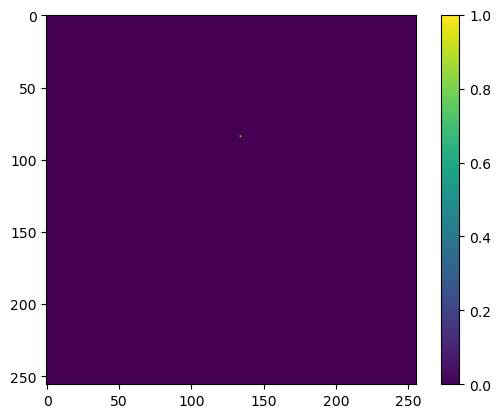

  0%|          | 0/125 [00:00<?, ?it/s]

['<|im_start|>user\nCan you tell me the approximate distance from <0> is denoted by <GEO> to <1> is referenced at <GEO>?<|im_end|>\n']
tensor([[151644,    872,    198,   6713,    498,   3291,    752,    279,  44868,
           6010,    504,    366,     15,     29,    374,   3371,   9253,    553,
            220, 151669,    311,    366,     16,     29,    374,  24784,    518,
            220, 151669,     30, 151645,    198, 151643, 151643, 151643, 151643,
         151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643]])
['<|im_start|>assistant\n<think>\n\n</think>\n\n<geo_think> Distance( <0> , <1> ) = 16763 </geo_think><|im_end|>\n']
tensor([[151644,  77091,    198, 151667,    271, 151668,    271,     27,  13052,
           5854,    766,     29,  31135,      7,    366,     15,     29,   1154,
            366,     16,     29,    873,    284,    220,     16,     21,     22,
             21,     18,    690,  13052,   5854,    766,     29, 151645,    198]])


In [20]:
num_pixels = []
for batch in dataloader_training_distance : #dataloader_training
    geo_features = batch["geo_feature"]  # (B, group_size, 1, H, W)
    for i in range(geo_features.size(0)):
        for j in range(geo_features.size(1)):
            num_pixels.append(geo_features[i, j].sum().item()-1)
            if num_pixels[-1] == 0:
                print("Found a geo feature with zero pixels!")
    if len(num_pixels) >= 256:
        break
print("Average number of pixels in geo features:", sum(num_pixels) / len(num_pixels))
#plt.hist(num_pixels, bins=50)
#plt.show()

plt.imshow(geo_features[i, j].squeeze().numpy())
plt.colorbar()
plt.show()
for batch in tqdm(dataloader_training):
    #continue
    print(batch["prompt_texts"][:1])
    print(batch["prompt_input_ids"][:1])
    print(batch["labels_texts"][:1])
    print(batch["labels"][:1])
    break

In [21]:
def find_answer_line(text):
    # Distance( , ) = <DIS> 
    pattern = r'LineLength\(\s*([^,]+)\s*\)\s*=\s*(\d+)'
    match = re.search(pattern, text)
    if match:
        return match.group(2)
    else:
        return None
def find_answer_polygon(text):
    # Distance( , ) = <DIS> 
    pattern = r'Area\(\s*([^,]+)\s*\)\s*=\s*(\d+)'
    match = re.search(pattern, text)
    if match:
        return match.group(2)
    else:
        return None
def find_answer_distance(text):
    # Distance( , ) = <DIS> 
    pattern = r'Distance\(\s*([^,]+)\s*,\s*([^,]+)\s*\)\s*=\s*(\d+)'
    match = re.search(pattern, text)
    if match:
        return match.group(3)
    else:
        return None
print(find_answer_line(" LineLength( <0> ) = 123 </s>"))
print(find_answer_polygon(" Area( <0> ) = 456 </s>"))
print(find_answer_distance(" Distance( <0> , <1> ) = 789 </s>"))

def evaluate_model_val_single(model, tokenizer, dataloader_validate, num_samples=5,printing=False,temperature=0.4,plot=False,find_answer=find_answer_line):
    model.eval()
    MAE = []
    predicts_list = []
    ground_truth_list = []

    with torch.no_grad():
        n=0
        for batch in dataloader_validate:
            system_prompt_ids = batch["prompt_input_ids"].to(device)
            geo = batch["geo_feature"].to(device)              # (B, geo_input_dim)
            labels = batch["labels"]#.to(device)
            labels_texts = batch["labels_texts"]
            query_mask = batch["prompt_attention_mask"].to(device)

            outputs = model.generate(query_ids=system_prompt_ids,
                                     geo_tensor=geo,
                                     query_mask=query_mask,
                                     max_new_tokens=len(labels[0])+20,
                                     temperature=temperature,
                                     top_k=50,
                                     top_p=0.95,
                                     do_sample=True)


            for i in range(len(batch["geo_feature"])):
                n+=1
                if len(MAE) >= num_samples or n >= num_samples:
                    break
                # extract '<GEO_THINKING> DISTANCE(<GEO_NAME>,<GEO_NAME>) = xxxx <GEO_THINKING_END>' number in geothinking
                result_ground_truth =  find_answer(labels_texts[i])
                generated_text = tokenizer.decode(outputs[i]) #, skip_special_tokens=True
                #print("Generated Text:", generated_text)
                result_predicted = find_answer(generated_text)

                if printing:
                    #print("Sample", n)
                    print("Ground Truth:", labels_texts[i])
                    print("Predicted   :", result_predicted)
                    print("Predicted   :", generated_text)
                    print("-----")

                if result_predicted is None:
                    continue
                try:
                    int(result_ground_truth)
                    int(result_predicted)
                except:
                    continue
                ground_truth_list.append(int(result_ground_truth))
                predicts_list.append(int(result_predicted))

                MAE.append(abs(int(result_ground_truth) - int(result_predicted)))
            if len(MAE) >= num_samples or n >= num_samples:
                break
                
    print(f"Evaluation {len(MAE)/num_samples} {len(MAE)} {num_samples} MAE: {np.mean(MAE)}") if len(MAE) > 0 else print("No valid predictions to compute MAE.")
    #model.train()
    if plot and len(ground_truth_list) > 0:
        plt.scatter(ground_truth_list, predicts_list, alpha=0.5)
        plt.plot([min(ground_truth_list), max(ground_truth_list)], [min(ground_truth_list), max(ground_truth_list)], color='red')
        plt.xlabel('Ground Truth Distance')
        plt.ylabel('Predicted Distance')
        plt.title('Predicted vs Ground Truth Distances')
        plt.show()

    return np.mean(MAE) if len(MAE) > 0 else None
        

123
456
789


In [22]:
def find_answer(text):
    # Distance( , ) = <DIS> 
    pattern = r'Distance\(\s*([^,]+)\s*,\s*([^)]+)\s*\)\s*=\s*(\d+)'
    match = re.search(pattern, text)
    if match:
        return match.group(3)
    else:
        return None

# match all the <geo_think> Distance( <0> , <2> ) = 11.2 in the text
def find_answer_distance_complex(text):
    """
    Find all Distance( <i> , <j> ) = value occurrences and return the values as floats.
    """
    pattern = re.compile(
        r'Distance\(\s*<\d+>\s*,\s*<\d+>\s*\)\s*=\s*([+-]?\d+(?:\.\d+)?)'
    )
    return [float(v) for v in pattern.findall(text)]

print(find_answer_distance_complex(" <geo_think> Distance( <0> , <2> ) = 11 , Distance( <1> , <2> ) = 4 </geo_think>"))
print(find_answer_distance_complex(" Distance( 0 , 1 ) = 27 </s>"))

def evaluate_model_val(model, tokenizer, dataloader_validate, num_samples=5,printing=False,temperature=0.4,plot=False):
    model.eval()
    MAE = []
    predicts_list = []
    ground_truth_list = []

    num_responses = []

    with torch.no_grad():
        n=0
        for batch in dataloader_validate:
            system_prompt_ids = batch["prompt_input_ids"].to(device)
            geo = batch["geo_feature"].to(device)              # (B, geo_input_dim)
            labels = batch["labels"]#.to(device)
            labels_texts = batch["labels_texts"]
            query_mask = batch["prompt_attention_mask"].to(device)

            outputs = model.generate(query_ids=system_prompt_ids,
                                     geo_tensor=geo,
                                     query_mask=query_mask,
                                     max_new_tokens=len(labels[0])+20,
                                     temperature=temperature,
                                     top_k=50,
                                     top_p=0.95,
                                     do_sample=True)


            for i in range(len(batch["geo_feature"])):
                n+=1
                if len(MAE) >= num_samples or n >= num_samples:
                    break
                # extract '<GEO_THINKING> DISTANCE(<GEO_NAME>,<GEO_NAME>) = xxxx <GEO_THINKING_END>' number in geothinking
                result_ground_truth =  find_answer_distance_complex(labels_texts[i])
                generated_text = tokenizer.decode(outputs[i]) #, skip_special_tokens=True
                #print("Generated Text:", generated_text)
                result_predicted = find_answer_distance_complex(generated_text)

                if printing:
                    #print("Sample", n)
                    print("Ground Truth:", labels_texts[i])
                    print("Predicted   :", result_predicted)
                    print("Predicted   :", generated_text)
                    print("-----")

                if result_predicted is None or len(result_predicted) == 0:
                    continue
                if len(result_ground_truth) != len(result_predicted):
                    continue
                ground_truth_list += result_ground_truth
                predicts_list += result_predicted

                num_responses.append(len(result_predicted))

                MAE+= [abs(gt - pred) for gt, pred in zip(result_ground_truth, result_predicted)]
            if len(MAE) >= num_samples or n >= num_samples:
                break
                
    print(f"Evaluation {num_samples} MAE: {np.mean(MAE)}") if len(MAE) > 0 else print("No valid predictions to compute MAE.")
    print(np.mean(num_responses))
    #model.train()
    if plot:
        plt.scatter(ground_truth_list, predicts_list, alpha=0.5)
        plt.plot([min(ground_truth_list), max(ground_truth_list)], [min(ground_truth_list), max(ground_truth_list)], color='red')
        plt.xlabel('Ground Truth Distance')
        plt.ylabel('Predicted Distance')
        plt.title('Predicted vs Ground Truth Distances')
        plt.show()

    return np.mean(MAE) if len(MAE) > 0 else None
        


[11.0, 4.0]
[]


In [23]:
save_name = None#'SpatialRGPT'
load = 'SpatialRGPT_lora2'
llm = None
embeddings_dim = 256
tuned_model = train_geomodel(llm, tokenizer, tuned_model=None, epochs=0, val_sample=2, lr=1e-4,train_dataloader=None,saving=save_name, load=load)
device = tuned_model.llm.device

Loading weights: 100%|██████████| 399/399 [00:03<00:00, 128.22it/s]


Loaded saved model for further training.
trainable params: 87,293,952 || all params: 8,278,029,312 || trainable%: 1.0545
Trainable params: 87293952 || All params: 8278029312 || %: 1.0545
Trainable params: 95971328 || All params: 8286706688 || %: 1.1581


In [ ]:
# save_name = None#'SpatialRGPT'
# load = None#'SpatialRGPT2'
# #llm = None
# embeddings_dim = 256
# tuned_model = train_geomodel(llm, tokenizer, tuned_model=None, epochs=0, val_sample=2, lr=1e-4,train_dataloader=None,saving=save_name, load=load)
# device = tuned_model.llm.device

# save_directory = '/home/chenchu/projects/LLMs/urban/models/checkpoints/'
# save_name = 'SpatialRGPT_lora2'
# utils.tools.save_model(tuned_model.llm, save_name, save_directory=save_directory)
# torch.save(
#     {
#         "geo_encoder": tuned_model.geo_encoder.state_dict(),
#         "geo_projector": tuned_model.geo_projector.state_dict(),
#     },
#     save_directory + save_name + "_geo_modules.pt"
# )
# # Save tokenizer (important)
# tuned_model.tokenizer.save_pretrained(save_directory + save_name + "_tokenizer")



In [24]:
mix_training_dataset = torch.utils.data.ConcatDataset([ dataset_training_polygon,dataset_training_line,dataset_training_distance, dataset_training_triplet])
mix_dataloader_training = DataLoader(mix_training_dataset, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))

In [25]:
import gc
torch.cuda.empty_cache()
gc.collect()

600

In [ ]:
save_name = 'SpatialRGPT_lora2'
load = None
best_triplet = 8000
#tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=2, val_sample=256, lr=1e-5,train_dataloader=dataloader_training_polygon,saving=save_name, load=load)
#tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=3, val_sample=256, lr=5e-5,train_dataloader=dataloader_training_line,saving=save_name, load=load)
tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=60, val_sample=256, lr=5e-5,train_dataloader=mix_dataloader_training,saving=save_name, load=load)

Loaded tuned model for further training.
trainable params: 87,293,952 || all params: 8,278,029,312 || trainable%: 1.0545
Trainable params: 87293952 || All params: 8278029312 || %: 1.0545
Trainable params: 95971328 || All params: 8286706688 || %: 1.1581


  0%|          | 0/500 [00:00<?, ?it/s]

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
100%|██████████| 500/500 [36:51<00:00,  4.42s/it]


Epoch 1 finished; epoch_loss=205.5222


100%|██████████| 500/500 [36:44<00:00,  4.41s/it]


Epoch 2 finished; epoch_loss=82.2186
Line Validation:
Evaluation 0.99609375 255 256 MAE: 347.24313725490197
Polygon Validation:
Evaluation 0.99609375 255 256 MAE: 2502.81568627451
Distance Validation:
Evaluation 0.99609375 255 256 MAE: 6974.086274509804
Multi:
Evaluation 64 MAE: 7386.25
4.0


100%|██████████| 500/500 [36:21<00:00,  4.36s/it]


Epoch 3 finished; epoch_loss=82.8184


100%|██████████| 500/500 [36:43<00:00,  4.41s/it]


Epoch 4 finished; epoch_loss=81.9028
Line Validation:
Evaluation 0.99609375 255 256 MAE: 386.4745098039216
Polygon Validation:
Evaluation 0.99609375 255 256 MAE: 2042.3921568627452
Distance Validation:
Evaluation 0.99609375 255 256 MAE: 7081.3372549019605
Multi:


In [26]:
save_name = 'SpatialRGPT_lora2'
load = None
best_triplet = 8000
#tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=2, val_sample=256, lr=1e-5,train_dataloader=dataloader_training_polygon,saving=save_name, load=load)
#tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=3, val_sample=256, lr=5e-5,train_dataloader=dataloader_training_line,saving=save_name, load=load)
tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=60, val_sample=256, lr=5e-5,train_dataloader=mix_dataloader_training,saving=save_name, load=load)

Loaded tuned model for further training.
trainable params: 87,293,952 || all params: 8,278,029,312 || trainable%: 1.0545
Trainable params: 87293952 || All params: 8278029312 || %: 1.0545
Trainable params: 95971328 || All params: 8286706688 || %: 1.1581


100%|██████████| 500/500 [36:26<00:00,  4.37s/it]


Epoch 1 finished; epoch_loss=81.3501


100%|██████████| 500/500 [36:19<00:00,  4.36s/it]


Epoch 2 finished; epoch_loss=81.2830
Line Validation:
Evaluation 0.99609375 255 256 MAE: 351.74901960784314
Polygon Validation:
Evaluation 0.99609375 255 256 MAE: 2587.321568627451
Distance Validation:
Evaluation 0.99609375 255 256 MAE: 7160.301960784313
Multi:
Evaluation 64 MAE: 5934.46875
4.0


...

100%|██████████| 500/500 [36:08<00:00,  4.34s/it]


Epoch 15 finished; epoch_loss=81.1060


100%|██████████| 500/500 [36:27<00:00,  4.37s/it]


Epoch 16 finished; epoch_loss=80.4633
Line Validation:
Evaluation 0.99609375 255 256 MAE: 367.84313725490193
Polygon Validation:
Evaluation 0.99609375 255 256 MAE: 2086.6392156862744
Distance Validation:
Evaluation 0.99609375 255 256 MAE: 7246.03137254902
Multi:


KeyboardInterrupt: 

In [27]:
save_name = 'SpatialRGPT_lora2'
load = None
best_triplet = 8000
#tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=2, val_sample=256, lr=1e-5,train_dataloader=dataloader_training_polygon,saving=save_name, load=load)
#tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=3, val_sample=256, lr=5e-5,train_dataloader=dataloader_training_line,saving=save_name, load=load)
tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=60, val_sample=256, lr=5e-5,train_dataloader=mix_dataloader_training,saving=save_name, load=load)

Loaded tuned model for further training.
trainable params: 87,293,952 || all params: 8,278,029,312 || trainable%: 1.0545
Trainable params: 87293952 || All params: 8278029312 || %: 1.0545
Trainable params: 88583936 || All params: 8279319296 || %: 1.0699


100%|██████████| 500/500 [12:52<00:00,  1.55s/it]


Epoch 1 finished; epoch_loss=82.3485


100%|██████████| 500/500 [12:52<00:00,  1.55s/it]


Epoch 2 finished; epoch_loss=81.6425
Line Validation:
Evaluation 0.99609375 255 256 MAE: 435.32941176470587
Polygon Validation:
Evaluation 0.99609375 255 256 MAE: 2233.3176470588237
Distance Validation:
Evaluation 0.99609375 255 256 MAE: 6354.38431372549
Multi:
Evaluation 64 MAE: 6926.979166666667
4.0


...

Epoch 15 finished; epoch_loss=80.8153


100%|██████████| 500/500 [12:57<00:00,  1.56s/it]


Epoch 16 finished; epoch_loss=79.9546
Line Validation:
Evaluation 0.99609375 255 256 MAE: 342.60392156862747
Polygon Validation:
Evaluation 0.99609375 255 256 MAE: 2284.176470588235
Distance Validation:
Evaluation 0.99609375 255 256 MAE: 6757.549019607844
Multi:
Evaluation 64 MAE: 7557.28125
4.0


 74%|███████▍  | 369/500 [09:45<03:27,  1.59s/it]


KeyboardInterrupt: 

In [50]:
save_name = 'SpatialRGPT_lora'
load = None
best_triplet = 8000
#tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=2, val_sample=256, lr=1e-5,train_dataloader=dataloader_training_polygon,saving=save_name, load=load)
#tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=3, val_sample=256, lr=5e-5,train_dataloader=dataloader_training_line,saving=save_name, load=load)
tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=60, val_sample=256, lr=5e-5,train_dataloader=mix_dataloader_training,saving=save_name, load=load)

Loaded tuned model for further training.
trainable params: 87,293,952 || all params: 8,278,029,312 || trainable%: 1.0545
Trainable params: 87293952 || All params: 8278029312 || %: 1.0545
Trainable params: 88583936 || All params: 8279319296 || %: 1.0699


  0%|          | 0/500 [00:00<?, ?it/s]

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
100%|██████████| 500/500 [12:49<00:00,  1.54s/it]


Epoch 1 finished; epoch_loss=159.4118


100%|██████████| 500/500 [12:49<00:00,  1.54s/it]


...

Epoch 51 finished; epoch_loss=79.8286


100%|██████████| 500/500 [12:44<00:00,  1.53s/it]


Epoch 52 finished; epoch_loss=80.5748
Line Validation:
Evaluation 0.99609375 255 256 MAE: 366.25882352941176
Polygon Validation:
Evaluation 0.99609375 255 256 MAE: 2798.156862745098
Distance Validation:
Evaluation 0.99609375 255 256 MAE: 6534.450980392156
Multi:
Evaluation 64 MAE: 7869.425
4.0


  2%|▏         | 10/500 [00:17<14:29,  1.77s/it]


KeyboardInterrupt: 

In [25]:
save_name = 'SpatialRGPT2'
load = None
best_triplet = 8000
#tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=2, val_sample=256, lr=1e-5,train_dataloader=dataloader_training_polygon,saving=save_name, load=load)
#tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=3, val_sample=256, lr=5e-5,train_dataloader=dataloader_training_line,saving=save_name, load=load)
tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=60, val_sample=256, lr=5e-5,train_dataloader=mix_dataloader_training,saving=save_name, load=load)

Loaded tuned model for further training.
trainable params: 87,293,952 || all params: 8,278,029,312 || trainable%: 1.0545
Trainable params: 87293952 || All params: 8278029312 || %: 1.0545
Trainable params: 88583936 || All params: 8279319296 || %: 1.0699


100%|██████████| 500/500 [13:26<00:00,  1.61s/it]


Epoch 1 finished; epoch_loss=180.4148
Line Validation:
Evaluation 0.99609375 255 256 MAE: 374.61176470588236
Polygon Validation:
Evaluation 0.99609375 255 256 MAE: 2073.1529411764704
Distance Validation:
Evaluation 0.99609375 255 256 MAE: 6852.239215686274
Multi:
Evaluation 64 MAE: 7792.361111111111
4.0


100%|██████████| 500/500 [13:47<00:00,  1.66s/it]


Epoch 2 finished; epoch_loss=86.6051


...

Epoch 58 finished; epoch_loss=83.2904


100%|██████████| 500/500 [13:48<00:00,  1.66s/it]


Epoch 59 finished; epoch_loss=84.0567
Line Validation:
Evaluation 0.99609375 255 256 MAE: 366.7843137254902
Polygon Validation:
Evaluation 0.99609375 255 256 MAE: 2491.035294117647
Distance Validation:
Evaluation 0.99609375 255 256 MAE: 7374.494117647058
Multi:
Evaluation 64 MAE: 6549.296875
4.0


100%|██████████| 500/500 [13:29<00:00,  1.62s/it]


Epoch 60 finished; epoch_loss=85.5047
Line Validation:
Evaluation 0.99609375 255 256 MAE: 400.27450980392155
Polygon Validation:
Evaluation 0.99609375 255 256 MAE: 2936.913725490196
Distance Validation:
Evaluation 0.99609375 255 256 MAE: 6557.317647058823
Multi:
Evaluation 64 MAE: 9905.359375
4.0


Evaluation 0.9921875 127 128 MAE: 5049.291338582677


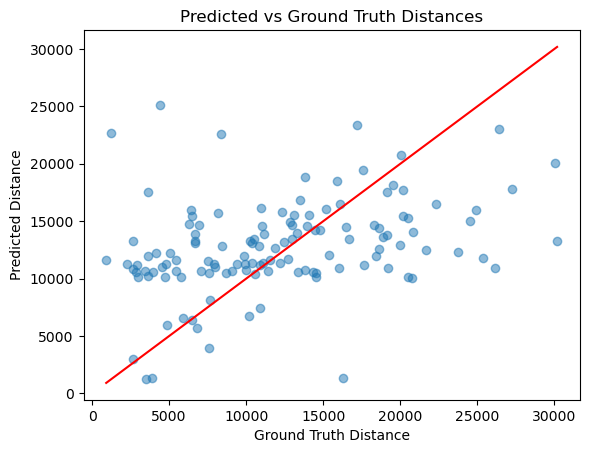

np.float64(5049.291338582677)

In [37]:
evaluate_model_val_single(tuned_model, tokenizer, dataloader_test_distance, num_samples=128,printing=False,temperature=0.4,plot=True,find_answer=find_answer_distance)

In [30]:
city = 'Beijing'#'LosAngeles'#'LosAngeles'#'Beijing'

benchmark_name = 'distance_Polygon_PolyLine'
benchmark_name = 'distance_Point_PolyLine'
#benchmark_name = 'distance_Polygon_Polygon'
#benchmark_name = 'PolyLine'
#benchmark_name = 'Area'
#benchmark_name = 'topo'
#benchmark_name = 'nearest_neighbor_Point_PolyLine'
#benchmark_name = 'nearest_neighbor_Polygon_PolyLine'

benchmark_name = benchmark_name + '_' + city
import pickle
with open(f'/home/chenchu/projects/LLMs/urban/data/benchmark/benchmark_{benchmark_name}.pkl', 'rb') as f:  #_updated
    selected_questions = pickle.load(f)


In [31]:
class GeoQuestionDataset(Dataset):
    def __init__(self, selected_questions):
        self.data = selected_questions

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        prompt = item['prompt']
        geo_representations = item['geo_representations']

        raster = []
        for shp in range(len(geo_representations)):
            geometry = shapely.from_wkt(geo_representations[shp])
            raster.append(torch.tensor(rasterize_geometry(geometry)).unsqueeze(0).float())  # (1, H, W)
        geo_representations = torch.concat(raster, dim=0)  # (N_geo, H, W)
        
        geo_names = item['geo_names']
        geo_embeddings = torch.tensor(item['geo_embeddings'])
        labels = item['labels']

        return {
            "prompt": prompt,
            "geo_feature": geo_representations,  # (representation_dimension,)
            "labels": labels
        }

def collate_fn_geoquestion_chattemplate2(batch: List[Dict], tokenizer):
    """
    Collates a batch of grouped samples.
    Assumes consistent group_size across samples.
    Returns:
      - prompt_input_ids: tokenized prompts
      - geo_feature: (B, group_size, dim)
      - input_ids: tokenized "text" (usually "Answer:\n")
      - attention_mask_text: attention mask for text
      - labels: tokenized labels_text
    """
    # geo features: (B, group_size, dim)
    geos = torch.zeros(len(batch), max([item["geo_feature"].size(0) for item in batch]), 256,256)  # (B,group_size,1,(H,W))
    for i, item in enumerate(batch):
        geos[i, :item["geo_feature"].size(0),:,:] = item["geo_feature"]
        # add one at the top left corner to indicate the presence of geo tokens
        geos[i, :item["geo_feature"].size(0),0,0] = 1.0

    geos = geos.unsqueeze(-3)  # (B, group_size, 1, (H, W))


    input_texts = [item["prompt"] for item in batch]
    input_texts=[
        [{"role": "user", "content": input_texts[b]}] for b in range(len(input_texts))
        ]
    input_texts = [
                tokenizer.apply_chat_template(
                    text,
                    tokenize=False,      # important: produce raw text first
                    #add_generation_prompt=True,
                    #enable_thinking=False,
                )
                for text in input_texts
            ]
    prompt_enc = tokenizer(input_texts, return_tensors="pt", padding=True,
                padding_side='right', add_special_tokens=True)

    labels_texts = [item["labels"] for item in batch]
    pure_labels = labels_texts.copy()
    labels_texts = [
        tokenizer.apply_chat_template(
            [{"role": "assistant", "content": labels_texts[b]}],
            tokenize=False,      # important: produce raw text first
            #add_generation_prompt=False,
            #enable_thinking=False,
        )
        for b in range(len(labels_texts))
    ]
    labels_enc = tokenizer(labels_texts, return_tensors="pt", padding=True,
                padding_side='right', add_special_tokens=False)

    return {
        "prompt_input_ids": prompt_enc["input_ids"],
        "prompt_texts": input_texts,
        "prompt_attention_mask": prompt_enc["attention_mask"],
        "geo_feature": geos,
        "labels": labels_enc["input_ids"],
        "labels_texts": labels_texts,
        "pure_labels": pure_labels,
        "labels_attention_mask": labels_enc["attention_mask"],
    }

dataloader_test = DataLoader(
    GeoQuestionDataset(selected_questions),
    batch_size=4,
    shuffle=False,
    collate_fn=lambda batch: collate_fn_geoquestion_chattemplate2(batch, tokenizer)
)

In [32]:
def evaluate_model_val2(model, tokenizer, dataloader_validate, num_samples=5,printing=False,temperature=0.4,plot=False,find_answer=find_answer_line):
    model.eval()
    MAE = []
    predicts_list = []
    ground_truth_list = []

    with torch.no_grad():
        n=0
        for batch in dataloader_validate:
            system_prompt_ids = batch["prompt_input_ids"].to(device)
            geo = batch["geo_feature"].to(device)              # (B, geo_input_dim)
            labels = batch["labels"]#.to(device)
            labels_texts = batch["pure_labels"]
            query_mask = batch["prompt_attention_mask"].to(device)

            outputs = model.generate(query_ids=system_prompt_ids,
                                     geo_tensor=geo,
                                     query_mask=query_mask,
                                     max_new_tokens=len(labels[0])+100,
                                     #eos_token_id=tokenizer.eos_token_id,
                                     temperature=temperature,
                                     top_k=50,
                                     top_p=0.95,
                                     do_sample=True)


            for i in range(len(batch["geo_feature"])):
                n+=1
                if len(MAE) >= num_samples or n >= num_samples:
                    break
                # extract '<GEO_THINKING> DISTANCE(<GEO_NAME>,<GEO_NAME>) = xxxx <GEO_THINKING_END>' number in geothinking
                try:
                    result_ground_truth =  float(labels_texts[i])
                except:
                    result_ground_truth = str(labels_texts[i])
                

                generated_text = tokenizer.decode(outputs[i]) #, skip_special_tokens=True
                #print("Generated Text:", generated_text)
                result_predicted = find_answer(generated_text)

                if printing:
                    #print("Sample", n)
                    print("Ground Truth:", labels_texts[i])
                    print("Predicted   :", result_predicted)
                    print("Predicted   :", generated_text)
                    print("-----")

                if result_predicted is None:
                    continue
                if benchmark_name != 'topo_US':
                    try:
                        float(result_ground_truth)
                        float(result_predicted)
                    except:
                        continue
                    ground_truth_list.append(float(result_ground_truth))
                    predicts_list.append(float(result_predicted))

                    MAE.append(abs(float(result_ground_truth) - float(result_predicted)))
                else:
                    ground_truth_list.append(str(result_ground_truth).lower())
                    predicts_list.append(str(result_predicted).lower())

                    if str(result_ground_truth).lower() == str(result_predicted).lower():
                        MAE.append(0)
                    else:
                        MAE.append(1)
            if len(MAE) >= num_samples or n >= num_samples:
                break
    if benchmark_name != 'topo_US':
        print(f"Evaluation {len(MAE)/num_samples} {len(MAE)} {num_samples} MAE: {np.mean(MAE)}") if len(MAE) > 0 else print("No valid predictions to compute MAE.")
    else:
        accuracy = (num_samples - sum(MAE)) / num_samples
        print(f"Evaluation {len(MAE)/num_samples} {len(MAE)} {num_samples} Accuracy: {accuracy}") if len(MAE) > 0 else print("No valid predictions to compute Accuracy.")   
    if plot and len(ground_truth_list) > 0:
        plt.scatter(ground_truth_list, predicts_list, alpha=0.5)
        plt.plot([min(ground_truth_list), max(ground_truth_list)], [min(ground_truth_list), max(ground_truth_list)], color='red')
        plt.xlabel('Ground Truth Distance')
        plt.ylabel('Predicted Distance')
        plt.title('Predicted vs Ground Truth Distances')
        plt.show()

    return np.mean(MAE) if len(MAE) > 0 else None
        

Evaluation 0.128 128 1000 MAE: 7237.6328125


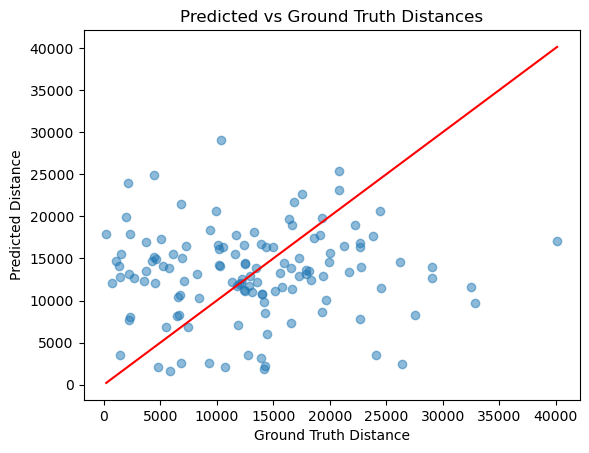

In [34]:
find_answer_function = find_answer_distance
mae_mean = evaluate_model_val2(tuned_model, tokenizer, dataloader_test, num_samples=1000,plot=True, printing=False, temperature=0.7, find_answer=find_answer_function)
        

In [29]:
qa_tokenizer = AutoTokenizer.from_pretrained("/data/public/LLMs/hf-Llama-3.3-70B-Instruct")#.to(device)
qa_llm = AutoModelForCausalLM.from_pretrained("/data/public/LLMs/hf-Llama-3.3-70B-Instruct",device_map="auto",dtype=torch.float16)#.to(device) #,dtype=torch.float16
qa_tokenizer.pad_token = qa_tokenizer.eos_token
qa_llm.config.pad_token_id = qa_tokenizer.eos_token_id

Loading weights: 100%|██████████| 723/723 [03:10<00:00,  3.80it/s]


In [35]:
def find_answer_qa(text):
    # <Answer> A </Answer>
    pattern = r'<Answer>\s*(.*?)\s*</Answer>'
    match = re.search(pattern, text)
    if match:
        return match.group(1)
    else:
        return None

def evaluate_model_Benchmark(model, tokenizer, QA_model, QA_tokenizer, dataloader, num_samples=5,temperature=0.4):
    model.eval()
    predicts_list = []
    ground_truth_list = []
    num_tokens_generated = []

    with torch.no_grad():
        n=0
        for batch in tqdm(dataloader):
            system_prompt_ids = batch["prompt_input_ids"].to(model.llm_device)
            input_texts = batch["prompt_texts"]
            geo = batch["geo_feature"]#.to(device)              # (B, geo_input_dim)
            labels = batch["labels"]#.to(device)
            labels_texts = batch["pure_labels"]
            query_mask = batch["prompt_attention_mask"]#.to(device)

            outputs = model.generate(query_ids=system_prompt_ids,
                                     geo_tensor=geo,
                                     query_mask=query_mask,
                                     max_new_tokens=100, #len(labels[0])+20
                                     temperature=temperature,
                                     top_k=50,
                                     top_p=0.95,
                                     do_sample=True)
            
            conversations = []
            batch_inputs = []
            # Find last </THINK> token in outputs
            think_start_token = '<geo_think>'
            think_end_token = '</geo_think>'
            for b in range(outputs.size(0)):

                text_deoded = tokenizer.decode(outputs[b], skip_special_tokens=True)
                think_start = text_deoded.find(think_start_token)
                think_end = text_deoded.find(think_end_token)
                if think_start != -1 and think_end != -1:
                    answer_text = text_deoded[think_start:think_end+len(think_end_token)].strip()
                else:
                    answer_text = text_deoded.strip()

                conversations.append([
                        {"role": "system", "content": " Output the answer MUST in such format: <Answer> <0> </Answer>. "+ " Output the answer directly." }, #Try to answer the question directly. Try to answer the question directly.
                        {"role": "user", "content": input_texts[b] + answer_text}
                ])

            conbersations_batch = [
                        QA_tokenizer.apply_chat_template(
                            conv,
                            tokenize=False,      # important: produce raw text first
                            #add_generation_prompt=True,
                            #enable_thinking=False
                        )
                        for conv in conversations
                    ]
            inputs = QA_tokenizer(
                conbersations_batch, #batch_inputs
                return_tensors="pt",
                padding=True,          # IMPORTANT
                truncation=True,
                padding_side='left',
                #add_special_tokens=False,
            ).to(QA_model.device)

            with torch.no_grad():
                outputs_qa = QA_model.generate(
                    **inputs,
                    max_new_tokens=32,
                    do_sample=False,
                    temperature=0.6,
                    pad_token_id=QA_tokenizer.eos_token_id,
                    # eos_token_id=QA_tokenizer.eos_token_id,
                )
            for b in range(outputs_qa.size(0)):
                len_input = inputs['input_ids'][b].shape[0]
                answer_predicted = QA_tokenizer.decode(outputs_qa[b][len_input:], skip_special_tokens=True)
                answer_predicted_clean = find_answer_qa(answer_predicted)
                answer_groundtruth = labels_texts[b]

                answer_all = QA_tokenizer.decode(outputs_qa[b], skip_special_tokens=True)
                think_start = answer_all.find(think_start_token) 
                start_to_end = answer_all[think_start:].strip()
                num_tokens_generated.append(len(tokenizer.encode(start_to_end)))

                if answer_predicted_clean is None:
                    predicts_list.append('Z')
                    ground_truth_list.append(answer_groundtruth)
                    #print(answer_predicted)
                    #print(input_texts[b])
                    #continue
                else:
                    predicts_list.append(answer_predicted_clean)
                    ground_truth_list.append(answer_groundtruth)

                    # if answer_predicted_clean!= answer_groundtruth:
                    #     print('------------------')
                    #     print('Think:', answer_all[think_start:])
                    #     #print('Predicted:', answer_predicted)
                    #     print('Ground Truth:', labels_texts[b])
                    #     print('------------------')

                #print(answer_predicted_clean, answer_groundtruth)
            accuracy = sum([1 for p, g in zip(predicts_list, ground_truth_list) if p == g]) / len(ground_truth_list)
            print(f"Benchmark Accuracy: {accuracy*100:.2f}%" , len(predicts_list)) 
            print(f"Average number of tokens generated in thinking: {np.mean(num_tokens_generated):.4f}" )
            if len(predicts_list) >= num_samples:
                break
            #break
    return predicts_list, ground_truth_list

predicts_list, ground_truth_list=evaluate_model_Benchmark(tuned_model, tokenizer, qa_llm, qa_tokenizer,
                                                          dataloader_test , num_samples=1280,temperature=0.6)


  0%|          | 0/32 [00:00<?, ?it/s]

  3%|▎         | 1/32 [00:11<05:43, 11.07s/it]

Benchmark Accuracy: 0.00% 4
Average number of tokens generated in thinking: 87.7500


  6%|▋         | 2/32 [00:22<05:32, 11.08s/it]

Benchmark Accuracy: 12.50% 8
Average number of tokens generated in thinking: 87.8750


...

Benchmark Accuracy: 29.17% 120
Average number of tokens generated in thinking: 87.6750


 97%|█████████▋| 31/32 [05:44<00:11, 11.11s/it]

Benchmark Accuracy: 28.23% 124
Average number of tokens generated in thinking: 87.6774


100%|██████████| 32/32 [05:55<00:00, 11.11s/it]

Benchmark Accuracy: 28.12% 128
Average number of tokens generated in thinking: 87.6719
